# CARE wind-turbine SCADA: a small GRU on daily deviation sequences

**Goal.** Test a recurrent network (one-layer GRU) against the CatBoost baseline, on the same labels, folds and checks
(`notebooks/care_catboost_baseline.md`, section 8), with an input built to avoid what made the earlier LSTM overfit
(hidden 128 on raw 15-minute channels: training ROC-AUC 0.99 against about 0.6 on validation).

- **Input.** One vector per day, the last 30 days: the baseline's daily deviation |rz| (each sensor against its own
  operating-point model, on the trailing baseline [t-180, t-60)). Two variants: the 20 sources ranked first by CatBoost
  SHAP inside each fold, or every sensor group plus 16 principal components of all sensors.
- **Training.** Self-supervised pretraining on normal days (predict the next day), then fine-tuning with event-balanced
  weights; small network, strong regularisation, early stopping on held-out turbines.
- **Output.** The daily risk for k = 7 ("inside an anomaly window or one starts within 7 days"), as the baseline. Fault
  onsets in B and C are logged at day resolution, so a finer output has no ground truth.

**Sections 1 to 7 are copied unchanged from `notebooks/care_catboost_baseline.ipynb`**; the daily deviation table and the
folds come from the baseline cache and the folds are checked against the saved file. New work starts at section 8.
Outputs go to `dataset/wind_turbine_scada_fault/cache/gru/`; the network code is `fault_detection/care_gru.py`.


In [1]:
import io
import re
import time
import warnings
import zlib
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
from catboost import CatBoostClassifier, Pool
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image as PILImage
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.notebook_repr_html", False)   # plain-text tables keep the notebook under the repo's 500 KB limit

ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "dataset" / "wind_turbine_scada_fault" / "raw"
CACHE = ROOT / "dataset" / "wind_turbine_scada_fault" / "cache"
OUT = CACHE / "catboost_baseline"
OUT.mkdir(parents=True, exist_ok=True)

REBUILD_FEATURES = False   # the daily deviation table (section 3); a few minutes
REBUILD_CV = False         # every cross-validated model run (sections 8 to 11)

FARMS = ["A", "B", "C"]
BASE_COLS = ["time_stamp", "asset_id", "id", "train_test", "status_type_id"]
# operating-point covariates: wind speed, active power, ambient temperature (10-minute averages)
COV = {"A": dict(ws="wind_speed_3_avg", p="power_30_avg", amb="sensor_0_avg"),
       "B": dict(ws="wind_speed_61_avg", p="power_62_avg", amb="sensor_8_avg"),
       "C": dict(ws="wind_speed_236_avg", p="power_6_avg", amb="sensor_7_avg")}
# Farm B has no relative wind direction; the yaw error is rebuilt from absolute wind direction minus nacelle direction
YAW_FROM = {"B": ("sensor_4_avg", "sensor_21_avg")}

MIN_ROWS_PER_DAY = 48      # of 144 ten-minute rows; fewer valid rows and the day is not used
BASE_FROM, BASE_TO = 180, 60   # trailing baseline of FIXED length: days [t-180, t-60) (why fixed: section 3)
REFIT_DAYS = 30            # the baseline is refitted every 30 days, so the gap to day t is 60 to 89 days
MIN_BASELINE_DAYS = 90     # valid days needed in the 120-day baseline window; otherwise "baseline period", unused
BASELINE_ROWS = 20_000     # rows sampled from the baseline window for the fits
CLIP = 10.0                # |robust z| is clipped here
HORIZONS = list(range(1, 8))
GRAY_DAYS = 7
REPAIR_DAYS = 14
SEEDS = [0, 1, 2]
FA_BUDGET = 1.0            # false alarms per turbine-month (30 negative days)
REARM_DAYS = 7             # a continuing alarm notifies again every 7 days, so a permanent alarm is not one false alarm
N_BOOT = 1000
CB_PARAMS = dict(depth=4, iterations=400, learning_rate=0.05, l2_leaf_reg=20, rsm=0.3, border_count=64,
                 loss_function="Logloss", thread_count=-1, verbose=False, allow_writing_files=False)
DAY = np.timedelta64(1, "D")

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#c9c8c2"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#c0392b"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})


def show(fig, dpi=80, colors=96):
    """Show a figure as a small palette PNG, so the notebook stays under the repo's 500 KB file limit.

    The full-resolution PNG of every figure is saved separately in the cache folder.
    """
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    img = PILImage.open(buf).convert("RGB").quantize(colors=colors)
    out = io.BytesIO()
    img.save(out, format="PNG", optimize=True)
    display(IPImage(out.getvalue()))


T0 = time.time()
print("root:", ROOT)

root: /Users/alexandrucojoaca/Documents/Smarthack


## 1. Columns: which ones go in, by rule

Every rule below is decided from column metadata or from the unlabelled distribution of the column, never from the labels:

- only `_avg` and `_std` statistics (`_min` and `_max` are redundant with them);
- counters out: flagged `is_counter`, energy units (Wh, VArh, kWh, kvarh) and Farm A's unsuffixed `sensor_44` to
  `sensor_51`;
- absolute wind direction and nacelle direction out (circular, and they only say where the wind comes from); relative
  wind direction is wrapped to +-180 and kept as a yaw error; Farm B has no relative direction, so its yaw error is
  rebuilt as absolute wind direction minus nacelle direction, wrapped; pitch and blade or motor positions are not circular
  and stay numeric;
- quasi-constant columns out (5th percentile equals the 95th) and columns with more than 50% missing out, both measured
  on a sample of all rows of the farm after cleaning;
- wind speed and ambient temperature are **covariates only**: they define the operating point, they are not deviation
  features. Active power becomes a power-curve residual (power against wind and ambient).

Sensor groups (for the group aggregates and the pooled model) come from keywords in the sensor description.

In [2]:
def category(desc, unit):
    d, u = str(desc).lower(), str(unit).lower()
    if "temp" in d:
        return "temperature"
    if "vibration" in d:
        return "vibration"
    if "pressure" in d or u in ("bar", "pa"):
        return "pressure"
    if "wind" in d or "yaw error" in d:
        return "wind"
    if "pitch" in d or "position" in d or "angle" in d:
        return "pitch"
    if "rpm" in u or "1/min" in u or "speed" in d or "rotor" in d:
        return "speed"
    if "power" in d or u in ("kw", "kvar", "kva", "kwh", "kvarh"):
        return "power"
    if u == "a" or "current" in d:
        return "electrical"
    if u == "v" or "voltage" in d:
        return "electrical"
    return "other"


def dataset_paths(farm):
    return sorted((RAW / f"Wind Farm {farm}" / "datasets").glob("comma_*.csv"), key=lambda p: int(p.stem.split("_")[1]))


def wrap180(x):
    return (x + 180.0) % 360.0 - 180.0


def column_table(farm):
    names = pacsv.open_csv(dataset_paths(farm)[0]).schema.names
    desc = pd.read_csv(RAW / f"Wind Farm {farm}" / "comma_feature_description.csv", encoding="latin-1")
    rows = []
    for n in names:
        if n in BASE_COLS:
            continue
        m = re.match(r"^(.*)_(avg|min|max|std)$", n)
        rows.append((n, m.group(1), m.group(2)) if m else (n, n, "val"))
    fm = pd.DataFrame(rows, columns=["column", "sensor_name", "stat"]).merge(
        desc.drop(columns="statistics_type"), on="sensor_name", how="left")
    if farm in YAW_FROM:
        fm.loc[len(fm)] = {"column": "yaw_error_avg", "sensor_name": "yaw_error", "stat": "avg", "unit": "deg",
                           "description": "Yaw error (absolute wind direction minus nacelle direction, wrapped)",
                           "is_angle": False, "is_counter": False}
    d, u = fm["description"].astype(str).str.lower(), fm["unit"].astype(str).str.lower()
    fm["group"] = [category(a, b) for a, b in zip(fm["description"], fm["unit"])]
    fm["is_temp"] = d.str.contains("temp")
    fm["rel_dir"] = d.str.contains("relative") & d.str.contains("direction")
    counter = fm["is_counter"].fillna(False).astype(bool) | u.isin(["wh", "varh", "kwh", "kvarh"]) | (fm["stat"] == "val")
    abs_dir = fm["is_angle"].fillna(False).astype(bool) & d.str.contains("direction") & ~fm["rel_dir"]
    reason = np.select(
        [counter, abs_dir, fm["stat"].isin(["min", "max"]),
         fm["column"].isin([COV[farm]["ws"], COV[farm]["amb"]])],
        ["counter", "absolute direction (circular)", "min/max (redundant)", "covariate only"], default="")
    fm["reason"] = reason
    fm.loc[fm["column"] == COV[farm]["p"], "role"] = "power-curve residual"
    fm["role"] = fm["role"].fillna("")
    return fm


def read_columns(path, cols):
    have = set(pacsv.open_csv(path).schema.names)
    t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(include_columns=["time_stamp"] + [c for c in cols if c in have]))
    ts = t["time_stamp"].to_numpy().astype("datetime64[s]")
    X = np.full((t.num_rows, len(cols)), np.nan, np.float32)
    for j, c in enumerate(cols):
        if c in have:
            X[:, j] = t[c].to_numpy(zero_copy_only=False)
    return ts, X


def clean(X, cols, farm, fm):
    """Dropped temperature readings to NaN, wrap relative directions, rebuild Farm B's yaw error, negative wind to NaN."""
    info = fm.set_index("column")
    for j, c in enumerate(cols):
        if c not in info.index:
            continue
        r = info.loc[c]
        if r["is_temp"] and r["stat"] != "std":
            X[X[:, j] == 0.0, j] = np.nan
        if r["rel_dir"] and r["stat"] == "avg":
            X[:, j] = wrap180(X[:, j])
    if farm in YAW_FROM and "yaw_error_avg" in cols:
        a, b = (cols.index(c) for c in YAW_FROM[farm])
        X[:, cols.index("yaw_error_avg")] = wrap180(X[:, a] - X[:, b])
    ws = cols.index(COV[farm]["ws"])
    X[X[:, ws] < 0, ws] = np.nan
    return X


def sample_stats(farm, fm, cands):
    """5th/95th percentile and missing share of every candidate column, on every 10th row of every dataset."""
    cols = cands + ([c for c in YAW_FROM.get(farm, ()) if c not in cands])

    def one(path):
        ts, X = read_columns(path, cols)
        return clean(X, cols, farm, fm)[::10]

    with ThreadPoolExecutor(max_workers=6) as ex:
        S = np.vstack(list(ex.map(one, dataset_paths(farm))))
    S = S[:, : len(cands)]
    return pd.DataFrame({"nan_frac": np.isnan(S).mean(0), "p05": np.nanpercentile(S, 5, axis=0),
                         "p95": np.nanpercentile(S, 95, axis=0)}, index=cands)


FM, DEV_COLS = {}, {}
inv_rows = []
for f in FARMS:
    fm = column_table(f)
    cand = fm.loc[fm["reason"].isin(["", "covariate only"]), "column"].tolist()
    st = sample_stats(f, fm, cand)
    fm = fm.merge(st, left_on="column", right_index=True, how="left")
    quasi = (fm["reason"] == "") & (fm["p05"] == fm["p95"])
    many_nan = (fm["reason"] == "") & (fm["nan_frac"] > 0.5)
    fm.loc[quasi, "reason"] = "quasi-constant"
    fm.loc[many_nan & ~quasi, "reason"] = ">50% missing"
    FM[f] = fm
    DEV_COLS[f] = fm.loc[fm["reason"] == "", "column"].tolist()
    inv_rows.append({"farm": f, "columns": len(fm), **fm["reason"].replace("", "kept").value_counts().to_dict()})

inv = pd.DataFrame(inv_rows).set_index("farm").fillna(0).astype(int)
display(inv)
grp_counts = pd.concat({f: FM[f].loc[FM[f]["reason"] == "", "group"].value_counts() for f in FARMS}, axis=1).fillna(0).astype(int)
display(grp_counts)
POOLED_GROUPS = [g for g in grp_counts.index if (grp_counts.loc[g] > 0).all() and g != "other"]
print("groups present in all three farms (pooled model):", POOLED_GROUPS)

      columns  kept  min/max (redundant)  counter  covariate only  absolute direction (circular)  quasi-constant
farm                                                                                                            
A          81    50                   18        8               2                              2               1
B         253   111                  114       16               2                              8               2
C         952   468                  476        0               2                              0               6

              A   B    C
group                   
temperature  24  49  153
power        10   8   34
electrical    6  22  144
speed         4   6   22
wind          3   8   13
pitch         2   2   21
other         1  10   17
vibration     0   6    8
pressure      0   0   56

groups present in all three farms (pooled model): ['temperature', 'power', 'electrical', 'speed', 'wind', 'pitch']


## 2. Timelines: which datasets of one turbine really overlap

The plan was to de-duplicate (turbine, day) across overlapping datasets. Checked here first: for every pair of datasets of
the same turbine whose timestamps overlap, the share of overlapping rows where wind speed, power and ambient temperature
are identical. Timestamps are anonymised per dataset, so an overlap of timestamps does not have to be an overlap of real
time.

In [3]:
def dataset_meta(farm):
    ev = pd.read_csv(RAW / f"Wind Farm {farm}" / "comma_event_info.csv", encoding="latin-1").set_index("event_id")
    cov = [COV[farm][k] for k in ("ws", "p", "amb")]

    def one(path):
        t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(include_columns=["time_stamp", "asset_id", "id", "train_test"] + cov))
        ts = t["time_stamp"].to_numpy().astype("datetime64[s]")
        ids = t["id"].to_numpy()
        e = int(path.stem.split("_")[1])
        r = ev.loc[e]
        meta = dict(farm=farm, event_id=e, asset_id=int(t["asset_id"][0].as_py()), label=r["event_label"],
                    start=ts.min(), end=ts.max(),
                    train_end=ts[t["train_test"].to_numpy(zero_copy_only=False) == "train"].max(), event_start=ts[ids == r["event_start_id"]][0],
                    event_end=ts[ids == r["event_end_id"]][0], n_rows=t.num_rows, description=r["event_description"])
        frame = pd.DataFrame(np.column_stack([t[c].to_numpy(zero_copy_only=False) for c in cov]), index=ts)
        return meta, frame

    with ThreadPoolExecutor(max_workers=6) as ex:
        res = list(ex.map(one, dataset_paths(farm)))
    return pd.DataFrame([m for m, _ in res]), {m["event_id"]: fr for m, fr in res}


def find_timelines(farm, meta, frames):
    parent = {e: e for e in meta["event_id"]}

    def root(e):
        while parent[e] != e:
            e = parent[e]
        return e

    pairs = []
    for a, g in meta.groupby("asset_id"):
        for i, j in combinations(g.sort_values("start")["event_id"], 2):
            x, y = frames[i], frames[j]
            common = x.index.intersection(y.index)
            if len(common) == 0:
                continue
            X, Y = x.loc[common].to_numpy(), y.loc[common].to_numpy()
            same = float(((np.abs(X - Y) < 1e-6) | (np.isnan(X) & np.isnan(Y))).all(axis=1).mean())
            pairs.append(dict(farm=farm, asset_id=a, dataset_1=i, dataset_2=j, overlap_days=round(len(common) / 144, 1),
                              identical_share=round(same, 4)))
            if same > 0.99:
                parent[root(i)] = root(j)
    comp = {e: root(e) for e in meta["event_id"]}
    pairs = pd.DataFrame(pairs)
    for _, r in pairs.iterrows():   # a clash inside one timeline would make the merge invalid
        assert r["identical_share"] > 0.99 or comp[r["dataset_1"]] != comp[r["dataset_2"]], r.to_dict()
    seg = {}
    for a, g in meta.groupby("asset_id"):
        roots = sorted({comp[e] for e in g["event_id"]}, key=lambda r_: g.loc[g["event_id"].map(comp) == r_, "start"].min())
        for k, r_ in enumerate(roots):
            for e in g.loc[g["event_id"].map(comp) == r_, "event_id"]:
                seg[e] = f"{farm}{a:02d}-{k}"
    return meta.assign(segment=meta["event_id"].map(seg)), pairs


META, PAIRS = {}, []
for f in FARMS:
    m, frames = dataset_meta(f)
    META[f], p = find_timelines(f, m, frames)
    PAIRS.append(p)
    del frames
PAIRS = pd.concat(PAIRS, ignore_index=True)
PAIRS["verdict"] = np.where(PAIRS["identical_share"] > 0.99, "same rows (merged)", "different data on the same timestamps")
display(PAIRS)
ALL_META = pd.concat(META.values(), ignore_index=True)
seg_tab = ALL_META.groupby("farm").agg(datasets=("event_id", "size"), turbines=("asset_id", "nunique"),
                                       timelines=("segment", "nunique"),
                                       anomaly=("label", lambda s: int((s == "anomaly").sum())))
seg_tab["overlapping pairs"] = PAIRS.groupby("farm").size()
seg_tab["of which identical"] = PAIRS[PAIRS["identical_share"] > 0.99].groupby("farm").size()
display(seg_tab.fillna(0).astype(int))


def windows_inside_other(meta, by):
    """Event onsets that fall inside the train part of another dataset of the same turbine (raw timestamps or timeline)."""
    n = {"anomaly": 0, "normal": 0}
    for _, r in meta.iterrows():
        others = meta[(meta[by] == r[by]) & (meta["event_id"] != r["event_id"])]
        if ((others["start"] <= r["event_start"]) & (others["train_end"] >= r["event_start"])).any():
            n[r["label"]] += 1
    return n


print("event onsets inside the train part of another dataset of the same turbine:")
for f in FARMS:
    print(f"  farm {f}: by raw timestamps {windows_inside_other(META[f], 'asset_id')}, "
          f"within verified timelines {windows_inside_other(META[f], 'segment')}")

   farm  asset_id  dataset_1  dataset_2  overlap_days  identical_share                                verdict
0     A         0          0         24         120.0           0.0000  different data on the same timestamps
1     A         0          0         73          76.3           0.0000  different data on the same timestamps
2     A         0         24         73         338.3           1.0000                     same rows (merged)
3     A        10         40         42         139.3           1.0000                     same rows (merged)
4     A        11         25         69         278.5           1.0000                     same rows (merged)
5     A        13         38         14         134.1           0.0001  different data on the same timestamps
6     A        13         14         84         193.9           1.0000                     same rows (merged)
7     A        21         22         72         313.7           1.0000                     same rows (merged)
8     B   

      datasets  turbines  timelines  anomaly  overlapping pairs  of which identical
farm                                                                               
A           22         5         17       11                  8                   5
B           15         9         14        6                  1                   1
C           58        22         54       27                 13                   4

event onsets inside the train part of another dataset of the same turbine:
  farm A: by raw timestamps {'anomaly': 3, 'normal': 4}, within verified timelines {'anomaly': 2, 'normal': 3}
  farm B: by raw timestamps {'anomaly': 1, 'normal': 0}, within verified timelines {'anomaly': 1, 'normal': 0}
  farm C: by raw timestamps {'anomaly': 6, 'normal': 3}, within verified timelines {'anomaly': 2, 'normal': 2}


## 3. Daily deviation table with a strictly trailing baseline

Per timeline (one turbine, the datasets merged in section 2, duplicate rows dropped), every 30 days the baseline is refitted
on the rows of days [m - 180, m - 60), where m is the first day of the 30-day block. Days in the block use that fit, so the
baseline always ends 60 to 89 days before the day it is applied to and never looks at the future or at the onset. A block
whose 120-day baseline window has fewer than 90 valid days gets no features (the "baseline period", unused).

**Why a fixed 120-day window and not t-365 to t-60.** Tried first: with the longer window the baseline grows with the
position in the timeline (it is short in the first months, a full ten months near the end), and the deviation index falls as
the baseline grows (median of the overall index, baseline under 120 days against over 300 days: Farm B 1.30 against 1.06,
Farm C 1.38 against 1.17). Positive days sit at the end of the timelines, so the features encoded *where in the dataset* a day
is, and the deviation rule came out below 0.5 ROC-AUC. A window of fixed length removes that (check at the end of section 5).

For each block and each deviation column:

1. **Operating-point residual.** The column is regressed on wind speed, active power and ambient temperature
   (standardised; terms 1, ws, ws^2, ws^3, p, p^2, amb, ws*p) over the baseline rows. Active power itself is regressed on
   wind and ambient only (the power-curve residual). Columns that do not depend on the operating point just get centred.
2. **Robust z.** The residual is centred on its baseline median and divided by 1.4826 * MAD (standard deviation if the MAD is
   zero), and the **absolute value is taken on every 10-minute row**, clipped at 10.
3. **Daily aggregation.** Mean and 95th percentile of |rz| per day, on days with at least 48 valid rows (wind speed and
   power present).

Also kept per day: the daily mean of wind speed, power and ambient temperature (context), and ambient temperature relative
to the baseline median.

In [4]:
def design(ws, p, amb, with_p=True):
    cols = [np.ones_like(ws), ws, ws ** 2, ws ** 3]
    if with_p:
        cols += [p, p ** 2]
    cols += [amb]
    if with_p:
        cols += [ws * p]
    return np.column_stack(cols)


def block_daily(RZ, doff, slot, nd):
    """Mean and 95th percentile of |rz| per day; RZ rows are 10-minute rows of one block."""
    arr = np.full((nd, 144, RZ.shape[1]), np.nan, np.float32)
    arr[doff, slot] = RZ
    cnt = np.isfinite(arr).sum(axis=1)
    mean = np.nansum(arr, axis=1) / np.maximum(cnt, 1)
    arr.sort(axis=1)
    k = np.clip(np.ceil(0.95 * cnt).astype(int) - 1, 0, 143)
    q95 = np.take_along_axis(arr, k[:, None, :], axis=1)[:, 0, :]
    bad = cnt < 24
    mean[bad], q95[bad] = np.nan, np.nan
    return mean, q95


def segment_table(job):
    farm, seg, event_ids = job
    fm = FM[farm]
    dev = DEV_COLS[farm]
    extra = [COV[farm]["ws"], COV[farm]["amb"]] + [c for c in YAW_FROM.get(farm, ()) if c not in dev]
    cols = dev + extra
    parts = [read_columns(RAW / f"Wind Farm {farm}" / "datasets" / f"comma_{e}.csv", cols) for e in event_ids]
    ts = np.concatenate([p[0] for p in parts])
    X = np.vstack([p[1] for p in parts])
    order = np.argsort(ts, kind="stable")
    ts, X = ts[order], X[order]
    keep = np.r_[True, ts[1:] != ts[:-1]]
    ts, X = ts[keep], clean(X[keep], cols, farm, fm)
    ws, amb = X[:, cols.index(COV[farm]["ws"])].astype(np.float64), X[:, cols.index(COV[farm]["amb"])].astype(np.float64)
    pj = dev.index(COV[farm]["p"])
    p = X[:, pj].astype(np.float64)
    XD = X[:, : len(dev)]

    dayv = ts.astype("datetime64[D]")
    day = dayv.astype(np.int64)
    slot = ((ts - dayv).astype("timedelta64[m]").astype(np.int64) // 10).clip(0, 143)
    d0, d1 = int(day.min()), int(day.max())
    nd = d1 - d0 + 1
    valid = np.isfinite(ws) & np.isfinite(p)
    nvalid = np.bincount(day[valid] - d0, minlength=nd)
    good_day = nvalid >= MIN_ROWS_PER_DAY
    row_good = valid & good_day[day - d0]
    fit_ok = row_good & np.isfinite(amb)

    M = np.full((nd, len(dev)), np.nan, np.float32)
    Q = np.full((nd, len(dev)), np.nan, np.float32)
    base_days = np.zeros(nd, np.int32)
    amb_base = np.full(nd, np.nan)
    rng = np.random.default_rng(zlib.crc32(seg.encode()))
    good_days_list = np.flatnonzero(good_day) + d0
    for m in range(d0, d1 + 1, REFIT_DAYS):
        lo, hi = m - d0, min(m - d0 + REFIT_DAYS, nd)
        nb = int(((good_days_list >= m - BASE_FROM) & (good_days_list < m - BASE_TO)).sum())
        base_days[lo:hi] = nb
        if nb < MIN_BASELINE_DAYS:
            continue
        ib = np.flatnonzero(fit_ok & (day >= m - BASE_FROM) & (day < m - BASE_TO))
        if len(ib) > BASELINE_ROWS:
            ib = np.sort(rng.choice(ib, BASELINE_ROWS, replace=False))
        ik = np.flatnonzero(fit_ok & (day >= m) & (day < m + REFIT_DAYS))
        if len(ik) == 0:
            continue
        cv = np.column_stack([ws, p, amb])
        mu, sd = cv[ib].mean(0), cv[ib].std(0)
        sd[sd < 1e-9] = 1.0
        zb, zk = (cv[ib] - mu) / sd, (cv[ik] - mu) / sd
        Db, Dk = design(*zb.T), design(*zk.T)
        Db_np, Dk_np = design(*zb.T, with_p=False), design(*zk.T, with_p=False)
        Xb = XD[ib].astype(np.float64)
        med = np.nanmedian(Xb, axis=0)
        okc = np.isfinite(med) & (np.isfinite(Xb).mean(0) >= 0.5)
        Xf = np.where(np.isfinite(Xb), Xb, med)
        beta = np.zeros((Db.shape[1], len(dev)))
        beta[:, okc] = np.linalg.lstsq(Db, Xf[:, okc], rcond=None)[0]
        bp = np.linalg.lstsq(Db_np, Xf[:, pj], rcond=None)[0]
        Rb = Xb - Db @ beta
        Rb[:, pj] = Xb[:, pj] - Db_np @ bp
        Rk = XD[ik].astype(np.float64) - Dk @ beta
        Rk[:, pj] = XD[ik, pj] - Dk_np @ bp
        c = np.nanmedian(Rb, axis=0)
        s = 1.4826 * np.nanmedian(np.abs(Rb - c), axis=0)
        sd_r = np.nanstd(Rb, axis=0)
        s = np.where(s > 1e-6, s, sd_r)
        okc &= np.isfinite(s) & (s > 1e-6)
        RZ = np.abs((Rk - c) / np.where(okc, s, np.nan)).astype(np.float32)
        np.minimum(RZ, CLIP, out=RZ)
        mean, q95 = block_daily(RZ, day[ik] - m, slot[ik], hi - lo)
        M[lo:hi], Q[lo:hi] = mean, q95
        amb_base[lo:hi] = np.median(amb[ib])

    def daily(v):
        s_ = np.bincount(day[row_good] - d0, weights=np.nan_to_num(v[row_good]), minlength=nd)
        c_ = np.bincount(day[row_good] - d0, weights=np.isfinite(v[row_good]).astype(float), minlength=nd)
        out = s_ / np.maximum(c_, 1)
        out[c_ < MIN_ROWS_PER_DAY / 2] = np.nan
        return out

    M[~good_day], Q[~good_day] = np.nan, np.nan
    df = pd.DataFrame({"farm": farm, "segment": seg, "day": np.arange(d0, d1 + 1), "n_valid": nvalid,
                       "base_days": base_days, "ctx_ws": daily(ws), "ctx_p": daily(p), "ctx_amb": daily(amb)})
    df["ctx_amb_rel"] = df["ctx_amb"] - amb_base
    dm = pd.DataFrame(M, columns=[f"{c}__m" for c in dev])
    dq = pd.DataFrame(Q, columns=[f"{c}__q" for c in dev])
    return pd.concat([df, dm, dq], axis=1)


DAILY = {}
for f in FARMS:
    path = OUT / f"daily_{f}.parquet"
    if path.exists() and not REBUILD_FEATURES:
        DAILY[f] = pd.read_parquet(path)
        continue
    t1 = time.time()
    jobs = [(f, s, g.sort_values("start")["event_id"].tolist()) for s, g in META[f].groupby("segment")]
    with ThreadPoolExecutor(max_workers=4) as ex:
        DAILY[f] = pd.concat(list(ex.map(segment_table, jobs)), ignore_index=True)
    DAILY[f].to_parquet(path)
    print(f"farm {f}: built in {time.time() - t1:.0f} s")
for f in FARMS:
    d = DAILY[f]
    usable = (d["n_valid"] >= MIN_ROWS_PER_DAY) & (d["base_days"] >= MIN_BASELINE_DAYS)
    print(f"farm {f}: {d['segment'].nunique()} timelines, {len(d):,} calendar days, {int(usable.sum()):,} usable days, "
          f"{len(DEV_COLS[f])} deviation columns")

farm A: 17 timelines, 7,123 calendar days, 4,446 usable days, 50 deviation columns
farm B: 14 timelines, 5,629 calendar days, 3,279 usable days, 111 deviation columns
farm C: 54 timelines, 21,112 calendar days, 12,568 usable days, 468 deviation columns


## 4. Labels

Unit: one (timeline, day); the anchor is the end of the day, so day t's features use data up to the end of day t. Anomaly
windows are taken from the anomaly datasets of the timeline, as whole days from the onset day `s` to the end day `e`
(onsets in B and C are logged at 00:00, so a day is the honest resolution); overlapping windows are merged. Windows of
normal datasets are ordinary negative days.

For a horizon k (1 to 7 days):

- **main target**: positive if day t is inside an anomaly window or a window starts in (t, t+k]. Cumulative and monotone in
  k by construction;
- **strict target**: positive if a window starts in (t, t+k]; days already inside a window are excluded;
- excluded from both: the 14 days after a window ends (repair), the 7-day gray zone before the first positive day
  (onset in (t+k, t+k+7]), days without a baseline (fewer than 90 valid days in [t-365, t-60)), and days with fewer than
  48 valid rows.

An **event** (for event recall) is one merged anomaly window.

In [5]:
def to_day(ts):
    return np.asarray(ts, dtype="datetime64[s]").astype("datetime64[D]").astype(np.int64)


def event_windows(meta):
    rows = []
    for seg, g in meta[meta["label"] == "anomaly"].groupby("segment"):
        w = sorted(zip(to_day(g["event_start"].to_numpy()), to_day(g["event_end"].to_numpy()), g["event_id"]))
        merged = []
        for s, e, eid in w:
            if merged and s <= merged[-1][1] + 1:
                merged[-1][1] = max(merged[-1][1], e)
                merged[-1][2].append(eid)
            else:
                merged.append([s, e, [eid]])
        for s, e, ids in merged:
            rows.append(dict(segment=seg, s=int(s), e=int(e), event_ids=",".join(map(str, ids))))
    ev = pd.DataFrame(rows)
    ev["asset_id"] = ev["segment"].map(meta.set_index("segment")["asset_id"].groupby(level=0).first())
    ev["turbine"] = ev["segment"].str.split("-").str[0]
    ev["length_days"] = ev["e"] - ev["s"] + 1
    return ev


def add_labels(d, ev):
    d = d.sort_values(["segment", "day"]).reset_index(drop=True)
    n = len(d)
    in_win = np.zeros(n, bool)
    repair = np.zeros(n, bool)
    dist = np.full(n, np.inf)        # days until the next onset (strictly after t)
    seg = d["segment"].to_numpy()
    day = d["day"].to_numpy()
    for _, r in ev.iterrows():
        m = seg == r["segment"]
        in_win |= m & (day >= r["s"]) & (day <= r["e"])
        repair |= m & (day > r["e"]) & (day <= r["e"] + REPAIR_DAYS)
        ahead = m & (day < r["s"])
        dist[ahead] = np.minimum(dist[ahead], r["s"] - day[ahead])
    usable = (d["n_valid"].to_numpy() >= MIN_ROWS_PER_DAY) & (d["base_days"].to_numpy() >= MIN_BASELINE_DAYS)
    excl = ~usable | (repair & ~in_win)
    d["in_window"], d["repair"], d["days_to_onset"], d["usable"] = in_win, repair, dist, usable
    for k in HORIZONS:
        pos = in_win | (dist <= k)
        gray = ~pos & (dist > k) & (dist <= k + GRAY_DAYS)
        d[f"y{k}"] = np.where(excl | gray, np.nan, pos.astype(float))
        spos = dist <= k
        d[f"ys{k}"] = np.where(excl | gray | in_win, np.nan, spos.astype(float))
    return d


EVENTS, DATA = {}, {}
for f in FARMS:
    EVENTS[f] = event_windows(META[f])
    d = add_labels(DAILY[f], EVENTS[f])
    d["asset_id"] = d["segment"].map(META[f].groupby("segment")["asset_id"].first())
    d["turbine"] = f + d["asset_id"].map("{:02d}".format)
    d["doy"] = pd.to_datetime(d["day"], unit="D").dt.dayofyear
    DATA[f] = d

rows = []
for f in FARMS:
    d, ev = DATA[f], EVENTS[f]
    r = {"farm": f, "anomaly datasets": int((META[f]["label"] == "anomaly").sum()), "merged events": len(ev),
         "event length (median days)": float(ev["length_days"].median()), "usable days": int(d["usable"].sum())}
    for k in (1, 7):
        y = d[f"y{k}"]
        r[f"main k={k}: labelled"] = int(y.notna().sum())
        r[f"main k={k}: positive %"] = round(100 * float(y.mean()), 2)
        r[f"strict k={k}: positives"] = int((d[f"ys{k}"] == 1).sum())
    ok = []
    for _, e in ev.iterrows():
        m = (d["segment"] == e["segment"]) & (d["day"] >= e["s"] - 7) & (d["day"] <= e["e"]) & (d["y7"] == 1)
        ok.append(bool(m.any()))
    ev["evaluable"] = ok
    r["events with labelled days"] = int(np.sum(ok))
    rows.append(r)
LABEL_TAB = pd.DataFrame(rows).set_index("farm").T
display(LABEL_TAB)
for f in FARMS:
    bad = EVENTS[f][~EVENTS[f]["evaluable"]]
    if len(bad):
        print(f"farm {f}: events with no labelled day in [s-7, e] (lost to missing data or no baseline):", bad["event_ids"].tolist())

farm                              A        B         C
anomaly datasets              11.00     6.00     27.00
merged events                 11.00     6.00     27.00
event length (median days)     8.00    37.50     15.00
usable days                 4446.00  3279.00  12568.00
main k=1: labelled          4322.00  3209.00  12291.00
main k=1: positive %           3.17     7.73      3.81
strict k=1: positives         11.00     6.00     26.00
main k=7: labelled          4322.00  3209.00  12289.00
main k=7: positive %           4.70     8.85      5.06
strict k=7: positives         77.00    42.00    180.00
events with labelled days     11.00     6.00     27.00

## 5. Features

From the daily table, by rule (the same rules for every farm; nothing is picked from a ranking):

- **per column** (every deviation column of section 1): the daily mean of |rz| (`__m`), its daily 95th percentile
  (`__q`), the 7-day rolling mean of `__m` (`__m_r7`) and the change of that rolling mean against the column's own days
  t-60 to t-30 (`__m_chg`);
- **per sensor group** (temperature, electrical, power, pitch, speed, wind/yaw, drivetrain vibration, pressure, other,
  and `all`): across the group's columns, the mean of `__m`, the max of `__m` and the mean of `__q`; each of the three gets
  the full set of time features: the day itself (`_d`), rolling means over 3, 7 and 14 days, the 7-day slope (`_s7`) and
  the change against days t-60 to t-30 (`_chg`);
- **context**: daily mean wind speed, power and ambient temperature (`ctx_*`). Ambient enters only as this covariate.

Rolling windows run over calendar days inside one timeline, ignore missing days and need at least half of the window.

Feature sets, by name:

| set | used by | content |
|---|---|---|
| `full` | **per-farm CatBoost** | every per-column, group and context feature of that farm |
| `pooled` | **pooled CatBoost** (one model, three farms) | group features of the six groups present in all three farms, plus `all`, plus wind, power and ambient relative to the baseline median (raw ambient would identify the farm) |
| `season` | season-only CatBoost | daily ambient, its 7-day mean, sin and cos of the day of year |
| `rule` | deviation-threshold rule | `grp_all_mean_r3`: 3-day mean of the overall deviation index, no model |

In [6]:
def rsum(A, w):
    c = np.vstack([np.zeros((1, A.shape[1])), np.cumsum(A, axis=0)])
    idx = np.arange(1, len(A) + 1)
    return c[idx] - c[np.maximum(idx - w, 0)]


def rmean(A, w, minp):
    mask = np.isfinite(A)
    s, c = rsum(np.where(mask, A, 0.0), w), rsum(mask.astype(float), w)
    out = s / np.maximum(c, 1)
    out[c < minp] = np.nan
    return out


def lag(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def slope(A, w=7, minp=4):
    mask = np.isfinite(A)
    t = np.arange(len(A), dtype=float)[:, None] * np.ones((1, A.shape[1]))
    y0, mt = np.where(mask, A, 0.0), np.where(mask, t, 0.0)
    n_, St, Stt = rsum(mask.astype(float), w), rsum(mt, w), rsum(mt * t, w)
    Sy, Sty = rsum(y0, w), rsum(y0 * t, w)
    den = n_ * Stt - St ** 2
    out = (n_ * Sty - St * Sy) / np.where(den > 0, den, np.nan)
    out[n_ < minp] = np.nan
    return out


def time_features(A, names):
    r7 = rmean(A, 7, 4)
    base = lag(rmean(A, 31, 10), 30)
    feats = {"d": A, "r3": rmean(A, 3, 2), "r7": r7, "r14": rmean(A, 14, 7), "s7": slope(A), "chg": r7 - base}
    return {f"{n}_{k}": v[:, i] for k, v in feats.items() for i, n in enumerate(names)}


def build_features(f):
    d = DATA[f]
    fm = FM[f].set_index("column")
    dev = DEV_COLS[f]
    groups = {g: [c for c in dev if fm.loc[c, "group"] == g] for g in fm.loc[dev, "group"].unique()}
    groups["all"] = dev
    out = []
    for seg, idx in d.groupby("segment", sort=False).indices.items():
        g_ = d.iloc[idx]
        Mm = g_[[f"{c}__m" for c in dev]].to_numpy(np.float64)
        Mq = g_[[f"{c}__q" for c in dev]].to_numpy(np.float64)
        cols = {}
        r7 = rmean(Mm, 7, 4)
        chg = r7 - lag(rmean(Mm, 31, 10), 30)
        for i, c in enumerate(dev):
            cols[f"{c}__m"], cols[f"{c}__q"], cols[f"{c}__m_r7"], cols[f"{c}__m_chg"] = Mm[:, i], Mq[:, i], r7[:, i], chg[:, i]
        G, names = [], []
        for gname, gc in groups.items():
            j = [dev.index(c) for c in gc]
            G += [np.nanmean(Mm[:, j], axis=1), np.nanmax(Mm[:, j], axis=1), np.nanmean(Mq[:, j], axis=1)]
            names += [f"grp_{gname}_mean", f"grp_{gname}_max", f"grp_{gname}_q"]
        cols.update(time_features(np.column_stack(G), names))
        cols["ctx_amb_r7"] = rmean(g_[["ctx_amb"]].to_numpy(np.float64), 7, 4)[:, 0]
        out.append(pd.DataFrame(cols, index=g_.index))
    F = pd.concat(out).loc[d.index].astype(np.float32)
    keys = d[["segment", "turbine", "asset_id", "day", "doy", "usable", "in_window", "repair", "days_to_onset", "n_valid",
              "ctx_ws", "ctx_p", "ctx_amb", "ctx_amb_rel"] + [f"y{k}" for k in HORIZONS] + [f"ys{k}" for k in HORIZONS]]
    F = pd.concat([keys.reset_index(drop=True), F.reset_index(drop=True)], axis=1)
    # diagnostics only, never model inputs: where the day sits in its timeline (positives sit at the end of anomaly datasets)
    F["pos_from_start"] = (F["day"] - F.groupby("segment")["day"].transform("min")).astype(np.float32)
    F["pos_to_end"] = (F.groupby("segment")["day"].transform("max") - F["day"]).astype(np.float32)
    F["doy_sin"] = np.sin(2 * np.pi * F["doy"] / 365.25).astype(np.float32)
    F["doy_cos"] = np.cos(2 * np.pi * F["doy"] / 365.25).astype(np.float32)
    F.insert(0, "farm", f)
    return F, groups


FEAT, GROUPS, SETS = {}, {}, {}
for f in FARMS:
    FEAT[f], GROUPS[f] = build_features(f)
    per_col = [c for c in FEAT[f].columns if "__" in c]
    grp = [c for c in FEAT[f].columns if c.startswith("grp_")]
    temp_cols = set(FM[f].loc[FM[f]["is_temp"], "column"])
    SETS[f] = {
        "full": per_col + grp + ["ctx_ws", "ctx_p", "ctx_amb"],
        "season": ["ctx_amb", "ctx_amb_r7", "doy_sin", "doy_cos"],
        "position": ["pos_from_start", "pos_to_end"],
        "no_ambient": per_col + grp + ["ctx_ws", "ctx_p"],
        "no_ambient_no_temp": [c for c in per_col if c.split("__")[0] not in temp_cols]
                              + [c for c in grp if not c.startswith("grp_temperature_")] + ["ctx_ws", "ctx_p"],
    }
POOLED_FEATS = [c for c in FEAT["A"].columns if c.startswith("grp_") and c.split("_")[1] in POOLED_GROUPS + ["all"]]
POOLED_FEATS += ["ctx_ws", "ctx_p", "ctx_amb_rel"]
assert all(c in FEAT[f].columns for f in FARMS for c in POOLED_FEATS)
KEYS = ["farm", "segment", "turbine", "asset_id", "day", "doy", "usable", "in_window", "repair", "days_to_onset",
        "n_valid", "ctx_amb", "doy_sin", "doy_cos"] + [f"y{k}" for k in HORIZONS] + [f"ys{k}" for k in HORIZONS]
FEAT["pooled"] = pd.concat([FEAT[f][KEYS + [c for c in POOLED_FEATS if c not in KEYS]] for f in FARMS], ignore_index=True)
SETS["pooled"] = {"pooled": POOLED_FEATS}
display(pd.DataFrame({f: {k: len(v) for k, v in SETS[f].items()} for f in FARMS}).T.assign(pooled=len(POOLED_FEATS)))
FORBIDDEN = {f"y{k}" for k in HORIZONS} | {f"ys{k}" for k in HORIZONS} | {
    "in_window", "repair", "days_to_onset", "usable", "n_valid", "pos_from_start", "pos_to_end", "status_type_id", "doy"}
for f in FARMS:   # guard: no label, status, row-count or position column in any model set
    for name, cols in SETS[f].items():
        if name != "position":
            assert not (set(cols) & FORBIDDEN) and not any("status" in c for c in cols), name
assert not (set(POOLED_FEATS) & FORBIDDEN)

   full  season  position  no_ambient  no_ambient_no_temp  pooled
A   347       4         2         346                 232     129
B   609       4         2         608                 394     129
C  2055       4         2        2054                1424     129

## 6. Cross-validation folds (the baseline's)

Whole turbines go into one fold, with every timeline and every day of that turbine:

- Farm A: leave one turbine out (5 folds); Farm B: leave one turbine out (9 folds); Farm C: 5 folds over 22 turbines,
  assigned by sorting turbines on their number of events (random tie-break by seed) and dealing them out in snake order, so
  each fold gets a similar number of events. Seeds 0, 1, 2 re-deal Farm C; for A and B only the CatBoost seed changes.
- The **pooled** scheme uses 5 folds over all 36 turbines: A's five turbines one per fold, B and C dealt the same way.

Inside every outer fold, the training turbines are split again into 3 inner groups (also by turbine). The inner fits give
(1) the number of trees, by early stopping on the held-out inner group, (2) out-of-fold scores on the training turbines,
from which the alarm threshold and the isotonic calibration are fitted. The outer test turbines are never seen by either.

In [7]:
def snake_folds(n_events, n_folds, seed):
    rng = np.random.default_rng(seed)
    t = n_events.index.to_numpy()
    order = np.lexsort((rng.random(len(t)), -n_events.to_numpy()))
    out = {}
    for i, j in enumerate(order):
        rnd, pos = divmod(i, n_folds)
        out[t[j]] = pos if rnd % 2 == 0 else n_folds - 1 - pos
    return out


fold_rows = []
for f in FARMS:
    turb = sorted(FEAT[f]["turbine"].unique())
    nev = EVENTS[f].groupby("turbine").size().reindex(turb, fill_value=0)
    for seed in SEEDS:
        per_farm = {t: i for i, t in enumerate(turb)} if f in ("A", "B") else snake_folds(nev, 5, seed)
        pooled = {t: i for i, t in enumerate(turb)} if f == "A" else snake_folds(nev, 5, seed)
        for t in turb:
            fold_rows.append(dict(scheme="per_farm", farm=f, turbine=t, seed=seed, fold=per_farm[t], n_events=int(nev[t])))
            fold_rows.append(dict(scheme="pooled", farm=f, turbine=t, seed=seed, fold=pooled[t], n_events=int(nev[t])))
FOLDS = pd.DataFrame(fold_rows)
SAVED_FOLDS = pd.read_parquet(OUT / "cv_folds.parquet")
pd.testing.assert_frame_equal(FOLDS.reset_index(drop=True), SAVED_FOLDS.reset_index(drop=True), check_dtype=False)
FOLDS = SAVED_FOLDS   # identical to the baseline's saved folds
display(FOLDS[FOLDS["seed"] == 0].groupby(["scheme", "farm", "fold"])["n_events"].agg(["size", "sum"])
        .rename(columns={"size": "turbines", "sum": "events"}).unstack("fold").fillna(0).astype(int))


def inner_groups(train_turbines, seed, n=3):
    t = np.array(sorted(train_turbines))
    np.random.default_rng(1000 + seed).shuffle(t)
    k = min(n, len(t))
    return [t[i::k] for i in range(k)]

              turbines                         events                        
fold                 0  1  2  3  4  5  6  7  8      0  1  2  3  4  5  6  7  8
scheme   farm                                                                
per_farm A           1  1  1  1  1  0  0  0  0      3  3  1  2  2  0  0  0  0
         B           1  1  1  1  1  1  1  1  1      0  0  0  1  1  1  1  1  1
         C           5  5  4  4  4  0  0  0  0      5  5  5  6  6  0  0  0  0
pooled   A           1  1  1  1  1  0  0  0  0      3  3  1  2  2  0  0  0  0
         B           1  2  2  2  2  0  0  0  0      1  1  1  1  2  0  0  0  0
         C           5  5  4  4  4  0  0  0  0      5  5  5  6  6  0  0  0  0

## 7. Training and evaluation engine

**Models.** CatBoost with fixed parameters for every farm, fold and target: depth 4, at most 400 trees, learning rate 0.05,
L2 20, 30% of the features considered per tree (`rsm`), 64 borders. The number of trees is the median early-stopping point
of the 3 inner fits (log loss on the held-out inner turbines); the final model is refitted on all training turbines with
that many trees. Baselines run through the same machinery: the **prevalence** (a constant), the **deviation rule** (the
score is `grp_all_mean_r3`, no fitting) and the **season-only** CatBoost.

**Alarms.** A day is *above threshold* when its score reaches the threshold of its fold. An *alarm day* needs 2 of the last
3 calendar days above threshold (persistence). An alarm notifies on its first day and again every 7 days while it lasts. A
**false alarm** is a notification on a negative day. The threshold is the lowest one at which the training turbines'
out-of-fold scores give at most **1 false alarm per turbine-month** (30 negative days).

**Metrics.** Day level: PR-AUC (average precision) against the prevalence, ROC-AUC, Brier score of the calibrated risk.
Event level: **recall** (an alarm day between 7 days before onset and the end of the window), the share caught before the
onset day, the median **lead time** (onset day minus first alarm day, negative = after onset) and the realised false-alarm
rate on the test turbines. Point estimates use the seed ensemble (mean calibrated risk; an alarm day needs a majority of
seeds); 95% intervals come from a cluster bootstrap over turbines (1000 resamples).

In [8]:
def seg_position(F):
    return F.groupby("segment", sort=False).cumcount().to_numpy()


def shifted(a, k, pos):
    out = np.zeros_like(a)
    out[k:] = a[:-k]
    out[pos < k] = False
    return out


def alarm_days(above, pos):
    s = above.astype(int) + shifted(above, 1, pos).astype(int) + shifted(above, 2, pos).astype(int)
    return s >= 2


def notifications(alarm, pos):
    start = alarm & ~shifted(alarm, 1, pos)
    run = np.cumsum(start)
    idx = np.arange(len(alarm))
    first = np.maximum.accumulate(np.where(start, idx, 0))
    return alarm & ((idx - first) % REARM_DAYS == 0) & (run > 0)


def fa_rate(alarm, y, pos):
    neg = y == 0
    months = neg.sum() / 30.0
    return (notifications(alarm, pos) & neg).sum() / months if months > 0 else np.nan


def choose_threshold(score, y, pos):
    ok = np.isfinite(score) & (y == 0)
    if ok.sum() == 0:
        return np.inf
    levels = np.r_[np.linspace(0.5, 0.99, 50), np.linspace(0.9902, 1.0, 50)]
    cand = np.unique(np.quantile(score[ok], levels))
    cand = np.r_[cand, np.nextafter(cand[-1], np.inf)]
    sc = np.where(np.isfinite(score), score, -np.inf)
    rates = np.array([fa_rate(alarm_days(sc >= c, pos), y, pos) for c in cand])
    good = rates <= FA_BUDGET
    tail_ok = np.flip(np.logical_and.accumulate(np.flip(good)))   # this and every higher candidate meet the budget
    return float(cand[np.argmax(tail_ok)]) if tail_ok.any() else np.inf


def run_cv(F, feats, target, scheme, kind="cb", seeds=SEEDS, score_col=None, want_importance=False):
    usable = F["usable"].to_numpy()
    y = F[target].to_numpy(float)
    lab = np.isfinite(y)
    turb = F["turbine"].to_numpy()
    pos = seg_position(F)
    X = F[feats].to_numpy(np.float32) if kind == "cb" else None
    preds, imps, info = [], [], []
    for seed in seeds:
        fo = FOLDS[(FOLDS["scheme"] == scheme) & (FOLDS["seed"] == seed)].set_index("turbine")["fold"]
        fold = pd.Series(turb).map(fo).to_numpy()
        score, pcal, thr_row = (np.full(len(F), np.nan) for _ in range(3))
        for k in np.unique(fold):
            te, tr = fold == k, fold != k
            oof = np.full(len(F), np.nan)
            n_star = np.nan
            if kind == "cb":
                fits = []
                for g in inner_groups(np.unique(turb[tr]), seed):
                    va = tr & np.isin(turb, g)
                    fit_m, ev_m = tr & ~va & lab & usable, va & lab & usable
                    if y[fit_m].sum() == 0 or ev_m.sum() == 0:
                        continue
                    m = CatBoostClassifier(**CB_PARAMS, random_seed=seed)
                    m.fit(X[fit_m], y[fit_m], eval_set=(X[ev_m], y[ev_m]), early_stopping_rounds=50, use_best_model=False)
                    fits.append((m, va, m.get_best_iteration() + 1))
                n_star = int(np.clip(np.median([b for *_, b in fits]), 30, CB_PARAMS["iterations"]))
                for m, va, _ in fits:
                    sel = va & usable
                    oof[sel] = m.predict_proba(X[sel], ntree_end=min(n_star, m.tree_count_))[:, 1]
                fit_all = tr & lab & usable
                final = CatBoostClassifier(**dict(CB_PARAMS, iterations=n_star), random_seed=seed)
                final.fit(X[fit_all], y[fit_all])
                sel = te & usable
                score[sel] = final.predict_proba(X[sel])[:, 1]
                if want_importance and seed == seeds[0]:
                    ev_rows = np.flatnonzero(te & usable & lab)
                    rng = np.random.default_rng(seed)
                    if len(ev_rows) > 3000:
                        ev_rows = np.sort(rng.choice(ev_rows, 3000, replace=False))
                    sv = final.get_feature_importance(Pool(X[ev_rows]), type="ShapValues")[:, :-1]
                    imps.append(pd.DataFrame({"feature": feats, "fold": k, "n": len(ev_rows),
                                              "pvc": final.get_feature_importance(type="PredictionValuesChange"),
                                              "mean_abs_shap": np.abs(sv).mean(0)}))
            elif kind == "rule":
                s_ = F[score_col].to_numpy(float)
                oof[tr & usable], score[te & usable] = s_[tr & usable], s_[te & usable]
            elif kind == "prev":
                prev = y[tr & lab & usable].mean()
                oof[tr & usable], score[te & usable] = prev, prev
            thr = choose_threshold(oof[tr], y[tr], pos[tr]) if kind != "prev" else np.inf
            cal = tr & lab & np.isfinite(oof)
            iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof[cal], y[cal])
            sel = te & np.isfinite(score)
            pcal[sel] = iso.predict(score[sel])
            thr_row[te] = thr
            info.append(dict(seed=seed, fold=k, n_trees=n_star, threshold=thr,
                             train_fa_rate=fa_rate(alarm_days(np.nan_to_num(oof[tr], nan=-np.inf) >= thr, pos[tr]), y[tr], pos[tr])))
        preds.append(pd.DataFrame({"seed": seed, "row": np.arange(len(F)), "fold": fold, "score": score, "p": pcal,
                                   "thr": thr_row}))
    return dict(pred=pd.concat(preds, ignore_index=True), info=pd.DataFrame(info),
                imp=pd.concat(imps, ignore_index=True) if imps else None)


def ensemble(F, res):
    P = res["pred"]
    pos = seg_position(F)
    n = len(F)
    p = P.groupby("row")["p"].mean().reindex(range(n)).to_numpy()
    score = P.groupby("row")["score"].mean().reindex(range(n)).to_numpy()
    al, ab = [], []
    for _, Ps in P.groupby("seed"):
        Ps = Ps.sort_values("row")
        above = np.nan_to_num(Ps["score"].to_numpy(), nan=-np.inf) >= Ps["thr"].to_numpy()
        ab.append(above)
        al.append(alarm_days(above, pos))
    return dict(p=p, score=score, above=np.mean(ab, 0) >= 0.5, alarm=np.mean(al, 0) >= 0.5,
                alarm_by_seed=al, p_by_seed=[Ps.sort_values("row")["p"].to_numpy() for _, Ps in P.groupby("seed")])


def per_turbine_parts(F, ev, p, alarm, target, horizon=7):
    """Per turbine: row indices for day metrics, events (detected, lead), false alarms and negative days."""
    y = F[target].to_numpy(float)
    pos = seg_position(F)
    notif = notifications(alarm, pos)
    turb = F["turbine"].to_numpy()
    seg = F["segment"].to_numpy()
    day = F["day"].to_numpy()
    parts = {}
    for t in np.unique(turb):
        m = turb == t
        rows = np.flatnonzero(m & np.isfinite(y) & np.isfinite(p))
        evs = []
        for _, e in ev[ev["turbine"] == t].iterrows():
            w = np.flatnonzero((seg == e["segment"]) & (day >= e["s"] - horizon) & (day <= e["e"]))
            if not (np.isfinite(y[w]) & (y[w] == 1)).any():
                continue
            hit = w[alarm[w]]
            evs.append((len(hit) > 0, e["s"] - day[hit[0]] if len(hit) else np.nan))
        parts[t] = dict(rows=rows, al=alarm[rows], events=evs, fa=int((notif & m & (y == 0)).sum()), neg=int((m & (y == 0)).sum()))
    return parts, y


def summarise(parts, y, p, sample=None):
    keys = list(parts) if sample is None else sample
    rows = np.concatenate([parts[t]["rows"] for t in keys])
    evs = [e for t in keys for e in parts[t]["events"]]
    yy, pp = y[rows], p[rows]
    al = np.concatenate([parts[t]["al"] for t in keys])
    out = {"prevalence": yy.mean() if len(yy) else np.nan}
    out["day_recall"] = al[yy == 1].mean() if (yy == 1).any() else np.nan
    out["day_specificity"] = 1 - al[yy == 0].mean() if (yy == 0).any() else np.nan
    out["pr_auc"] = average_precision_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan
    out["roc_auc"] = roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan
    wa = [(roc_auc_score(y[parts[t]["rows"]], p[parts[t]["rows"]]), y[parts[t]["rows"]].sum()) for t in keys
          if 0 < y[parts[t]["rows"]].sum() < len(parts[t]["rows"])]
    out["within_turbine_auc"] = np.average([a for a, _ in wa], weights=[w for _, w in wa]) if wa else np.nan
    out["brier"] = brier_score_loss(yy, pp) if len(yy) else np.nan
    det = np.array([d for d, _ in evs], bool)
    lead = np.array([l for d, l in evs if d], float)
    out["events"] = len(evs)
    out["recall"] = det.mean() if len(det) else np.nan
    out["recall_before_onset"] = np.mean([d and l >= 1 for d, l in evs]) if len(evs) else np.nan
    out["median_lead_days"] = np.median(lead) if len(lead) else np.nan
    neg = sum(parts[t]["neg"] for t in keys)
    out["fa_per_turbine_month"] = sum(parts[t]["fa"] for t in keys) / (neg / 30.0) if neg else np.nan
    return out


def evaluate(F, res, target, ev, mask_farm=None, n_boot=N_BOOT, seed=0):
    E = ensemble(F, res)
    parts, y = per_turbine_parts(F, ev, E["p"], E["alarm"], target)
    if mask_farm is not None:
        parts = {t: v for t, v in parts.items() if t.startswith(mask_farm)}
    point = summarise(parts, y, E["p"])
    rng = np.random.default_rng(seed)
    keys = list(parts)
    boots = [summarise(parts, y, E["p"], list(rng.choice(keys, len(keys), replace=True))) for _ in range(n_boot)]
    B = pd.DataFrame(boots)
    by_seed = []
    for a, p_ in zip(E["alarm_by_seed"], E["p_by_seed"]):
        ps, _ = per_turbine_parts(F, ev, p_, a, target)
        if mask_farm is not None:
            ps = {t: v for t, v in ps.items() if t.startswith(mask_farm)}
        by_seed.append(summarise(ps, y, p_))
    return dict(point=point, boot=B, by_seed=pd.DataFrame(by_seed), E=E, parts=parts, y=y)


def oracle_recall(F, score, target, ev, farm=None, horizon=7):
    """Recall at exactly the budget on the TEST turbines (threshold picked on the test set: for comparing rankings only)."""
    y = F[target].to_numpy(float)
    pos = seg_position(F)
    m = np.ones(len(F), bool) if farm is None else F["turbine"].str.startswith(farm).to_numpy()
    sc = np.where(np.isfinite(score) & m, score, -np.inf)
    ok = np.isfinite(score) & m & (y == 0)
    cand = np.unique(np.quantile(score[ok], np.r_[np.linspace(0.5, 0.99, 50), np.linspace(0.9902, 1.0, 50)]))
    ym = np.where(m, y, np.nan)
    for c in cand:
        al = alarm_days(sc >= c, pos)
        if fa_rate(al, ym, pos) <= FA_BUDGET:
            parts, _ = per_turbine_parts(F, ev, np.nan_to_num(score), al, target, horizon)
            parts = {t: v for t, v in parts.items() if farm is None or t.startswith(farm)}
            evs = [d for v in parts.values() for d, _ in v["events"]]
            return float(np.mean(evs)) if evs else np.nan
    return 0.0


def perm_p(is_anomaly, score, n=5000, seed=0):
    """One-sided permutation p-value of the dataset-level AUC (labels shuffled across datasets)."""
    a = np.asarray(is_anomaly, bool)
    r = pd.Series(score).rank().to_numpy()
    n1, n0 = a.sum(), (~a).sum()
    obs = (r[a].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    rng = np.random.default_rng(seed)
    perm = np.array([(r[rng.permutation(a)].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) for _ in range(n)])
    return float((np.sum(perm >= obs) + 1) / (n + 1))


def matched_eval(F, E, meta, farm, before=7, after=14):
    """Anomaly datasets against normal datasets at the same position: days [s-7, s+14] around each dataset's own window start."""
    seg, day = F["segment"].to_numpy(), F["day"].to_numpy()
    y = F["y7"].to_numpy(float)
    rows, d_idx = [], []
    for _, r in meta[meta["farm"] == farm].iterrows():
        s = to_day([r["event_start"]])[0]
        w = np.flatnonzero((seg == r["segment"]) & (day >= s - before) & (day <= s + after) & np.isfinite(E["score"]))
        if len(w) == 0:
            continue
        rows.append(dict(label=r["label"], max_score=np.max(E["score"][w]), alarm=bool(E["alarm"][w].any())))
        d_idx.append(w[np.isfinite(y[w])])
    R = pd.DataFrame(rows)
    d_idx = np.unique(np.concatenate(d_idx))
    yy = y[d_idx]
    return {"dataset AUC (max score)": roc_auc_score(R["label"] == "anomaly", R["max_score"]),
            "permutation p": perm_p(R["label"] == "anomaly", R["max_score"]),
            "day AUC": roc_auc_score(yy, E["score"][d_idx]) if 0 < yy.sum() < len(yy) else np.nan,
            "alarm in anomaly datasets": R.loc[R["label"] == "anomaly", "alarm"].mean(),
            "alarm in normal datasets": R.loc[R["label"] == "normal", "alarm"].mean(),
            "n anomaly / normal": f"{(R['label'] == 'anomaly').sum()} / {(R['label'] == 'normal').sum()}"}


def matched_pre_onset(F, score, meta, farm, before=7):
    """Strict target at the same position: days [s-7, s-1] before each dataset's own window start, anomaly vs normal."""
    seg, day = F["segment"].to_numpy(), F["day"].to_numpy()
    rows = []
    for _, r in meta[meta["farm"] == farm].iterrows():
        s = to_day([r["event_start"]])[0]
        w = np.flatnonzero((seg == r["segment"]) & (day >= s - before) & (day <= s - 1) & np.isfinite(score))
        if len(w):
            rows.append(dict(label=r["label"], max_score=np.max(score[w]), mean_score=np.mean(score[w])))
    R = pd.DataFrame(rows)
    a = R["label"] == "anomaly"
    return {"dataset AUC (max score, 7 d before)": roc_auc_score(a, R["max_score"]),
            "permutation p": perm_p(a, R["max_score"]),
            "dataset AUC (mean score, 7 d before)": roc_auc_score(a, R["mean_score"]),
            "n anomaly / normal": f"{a.sum()} / {(~a).sum()}"}

## 8. GRU setup: inputs, event weights, CatBoost inner scores and the SHAP selection

**Two input variants**, both one vector per day, a window of the last 30 days ending at day t:

- **`GRU, SHAP top 20`**: the 20 sources with the largest CatBoost |SHAP|, summed over all features derived from a source
  (a source is one sensor column, or one sensor group). A column enters as its daily mean |rz| (`__m`) and daily 95th
  percentile (`__q`), a group as its daily mean, max and mean 95th percentile (`grp_<g>_mean_d`, `_max_d`, `_q_d`); the GRU
  sees the sequence itself, so the rolling, slope and change features CatBoost needs are not passed. Plus daily wind and
  power (`ctx_ws`, `ctx_p`). Ambient temperature never enters (season).
- **`GRU, groups + PCA 16`**: every group's daily mean, max and 95th percentile (A 24, B 27, C 30), 16 principal
  components of the daily |rz| of every column (A 50, B 111, C 468 columns), and `ctx_ws`, `ctx_p`.

**No leakage in the selection.** The SHAP ranking is recomputed inside every fit: the final GRU of an outer fold uses the
ranking of the CatBoost trained on that fold's training turbines; each inner GRU fit uses the ranking of the inner CatBoost
trained without its held-out inner group. The PCA is fitted on the negative days of the fit's training turbines only.
SHAP is computed on training rows (up to 3000 labelled days).

**Preprocessing** inside every fit: `log1p` on the |rz| inputs, standardised on the fit's training rows; missing days
become 0 (the training mean); padded days before a timeline starts are zeros too. A "day missing" flag is not an input:
missing data goes with downtime, which goes with the label.

**Event weights.** Each anomaly event gets the same total weight, and the positive days together weigh as much as the
negative days. Otherwise Farm B's long windows (median 37.5 days) would dominate. The isotonic calibration afterwards
returns the scores to probabilities.

**Model and training** (fixed, not tuned on the results): one-layer GRU, hidden 16, dropout 0.4, AdamW lr 1e-3, weight
decay 1e-2, batch 128, Gaussian input noise 0.1, gradient clipping 1.0.
1. *Pretraining*, 15 epochs: predict the next day's inputs, on windows ending at negative days of the training turbines.
2. *Fine-tuning*: the label (weighted BCE) plus 0.1 x the next-day loss, at most 30 epochs, early stopping on the
   held-out inner group's ROC-AUC (patience 5). The final fit uses the median best epoch of the inner fits, as CatBoost
   uses the median early-stopping point.
3. Two networks (seeds) per fit, logits averaged; three fold seeds, as the baseline.

**CatBoost** is refitted with the baseline's seeds and parameters, because the blend and the selection need its inner
out-of-fold scores and inner models. Its test scores are checked against the saved baseline run.

In [9]:
import os
import sys

from joblib import Parallel, delayed
from scipy.stats import spearmanr

sys.path.insert(0, str(ROOT / "fault_detection"))
os.environ["PYTHONPATH"] = str(ROOT / "fault_detection") + os.pathsep + os.environ.get("PYTHONPATH", "")
import care_gru  # noqa: E402

OUT2 = CACHE / "gru"
OUT2.mkdir(parents=True, exist_ok=True)
REBUILD_CB = False
REBUILD_GRU = False
TOP_K = 20
N_JOBS = 5
RUNS = pd.read_pickle(OUT / "cv_runs.pkl")
ALL_EVENTS = pd.concat(EVENTS.values(), ignore_index=True)
GRU_VARIANTS = [("GRU, SHAP top 20", "shap20"), ("GRU, groups + PCA 16", "grp_pca")]
print("GRU settings:", care_gru.DEFAULTS)


def candidates(f):
    dev = DEV_COLS[f]
    grp = [f"grp_{g}_{s}_d" for g in GROUPS[f] for s in ("mean", "max", "q")]
    cols = [f"{c}__m" for c in dev] + [f"{c}__q" for c in dev] + grp + ["ctx_ws", "ctx_p"]
    return cols, grp


def source_of(feat):
    if "__" in feat:
        return feat.split("__")[0]
    if feat.startswith("grp_"):
        return "grp_" + feat.split("_")[1]
    return None


def source_inputs(src):
    if src.startswith("grp_"):
        g = src[4:]
        return [f"grp_{g}_mean_d", f"grp_{g}_max_d", f"grp_{g}_q_d"]
    return [f"{src}__m", f"{src}__q"]


def top_sources(model, X, rows, feats, seed):
    rng = np.random.default_rng(seed)
    if len(rows) > 3000:
        rows = np.sort(rng.choice(rows, 3000, replace=False))
    sv = np.abs(model.get_feature_importance(Pool(X[rows]), type="ShapValues")[:, :-1]).mean(0)
    s = pd.Series(sv, index=feats).groupby([source_of(c) or "ctx" for c in feats]).sum().drop("ctx", errors="ignore")
    return s.sort_values(ascending=False).head(TOP_K).index.tolist()


def event_weights(F, ev):
    y = F["y7"].to_numpy(float)
    seg, day = F["segment"].to_numpy(), F["day"].to_numpy()
    w = np.where(y == 0, 1.0, 0.0)
    pos = y == 1
    owner = np.full(len(F), -1)
    for i, e in ev.reset_index(drop=True).iterrows():
        m = pos & (seg == e["segment"]) & (day >= e["s"] - 7) & (day <= e["e"]) & (owner < 0)
        owner[m] = i
    n_ev = len(np.unique(owner[owner >= 0]))
    per_event = (y == 0).sum() / max(n_ev, 1)
    for i in np.unique(owner[owner >= 0]):
        w[owner == i] = per_event / (owner == i).sum()
    w[pos & (owner < 0)] = np.median(w[owner >= 0]) if (owner >= 0).any() else 1.0
    return w


def cb_fold(F, feats, fseed, k):
    """The baseline's CatBoost on one outer fold: inner out-of-fold scores, test scores and the SHAP selections."""
    usable = F["usable"].to_numpy()
    y = F["y7"].to_numpy(float)
    lab = np.isfinite(y)
    turb = F["turbine"].to_numpy()
    X = F[feats].to_numpy(np.float32)
    fo = FOLDS[(FOLDS["scheme"] == "per_farm") & (FOLDS["seed"] == fseed)].set_index("turbine")["fold"]
    fold = pd.Series(turb).map(fo).to_numpy()
    te, tr = fold == k, fold != k
    groups = inner_groups(np.unique(turb[tr]), fseed)
    oof, test = np.full(len(F), np.nan), np.full(len(F), np.nan)
    fits, sel = [], {}
    for gi, g in enumerate(groups):
        va = tr & np.isin(turb, g)
        fit_m, ev_m = tr & ~va & lab & usable, va & lab & usable
        if y[fit_m].sum() == 0 or ev_m.sum() == 0:
            continue
        m = CatBoostClassifier(**CB_PARAMS, random_seed=fseed)
        m.fit(X[fit_m], y[fit_m], eval_set=(X[ev_m], y[ev_m]), early_stopping_rounds=50, use_best_model=False)
        fits.append((m, va, m.get_best_iteration() + 1))
        sel[gi] = top_sources(m, X, np.flatnonzero(fit_m), feats, fseed)
    n_star = int(np.clip(np.median([b for *_, b in fits]), 30, CB_PARAMS["iterations"]))
    for m, va, _ in fits:
        s_ = va & usable
        oof[s_] = m.predict_proba(X[s_], ntree_end=min(n_star, m.tree_count_))[:, 1]
    fit_all = tr & lab & usable
    final = CatBoostClassifier(**dict(CB_PARAMS, iterations=n_star), random_seed=fseed)
    final.fit(X[fit_all], y[fit_all])
    test[te & usable] = final.predict_proba(X[te & usable])[:, 1]
    sel["final"] = top_sources(final, X, np.flatnonzero(fit_all), feats, fseed)
    return dict(oof=oof, test=test, sel=sel, groups=groups, fold=fold, n_star=n_star)


CB_PATH = OUT2 / "catboost_inner.pkl"
CB = pd.read_pickle(CB_PATH) if CB_PATH.exists() and not REBUILD_CB else {}
for f in FARMS:
    folds_f = sorted(FOLDS.query("scheme == 'per_farm' and farm == @f")["fold"].unique())
    for fseed in SEEDS:
        for k in folds_f:
            if (f, fseed, k) not in CB:
                t1 = time.time()
                CB[(f, fseed, k)] = cb_fold(FEAT[f], SETS[f]["full"], fseed, k)
                print(f"  CatBoost {f} seed {fseed} fold {k}: {time.time() - t1:.0f} s")
    pd.to_pickle(CB, CB_PATH)

rep = []
for f in FARMS:
    old = RUNS[f"{f}|full|y7"]["pred"]
    for fseed in SEEDS:
        new = np.nanmax(np.stack([v["test"] for (ff, s, _), v in CB.items() if ff == f and s == fseed]), axis=0)
        b = old[old["seed"] == fseed].sort_values("row")["score"].to_numpy()
        m = np.isfinite(new) | np.isfinite(b)
        rep.append({"farm": f, "seed": fseed, "max |score difference| vs baseline": float(np.nanmax(np.abs(new[m] - b[m])))})
display(pd.DataFrame(rep).set_index(["farm", "seed"]))

GRU settings: {'window': 30, 'hidden': 16, 'dropout': 0.4, 'lr': 0.001, 'weight_decay': 0.01, 'batch': 128, 'noise': 0.1, 'pretrain_epochs': 15, 'max_epochs': 30, 'patience': 5, 'aux_weight': 0.1, 'n_pca': 16, 'net_seeds': (0, 1)}


           max |score difference| vs baseline
farm seed                                    
A    0                                    0.0
     1                                    0.0
     2                                    0.0
B    0                                    0.0
     1                                    0.0
     2                                    0.0
C    0                                    0.0
     1                                    0.0
     2                                    0.0

**Which sources the SHAP selection picks.** Share of the final (outer-fold) selections that contain each source, top 15
per farm. A source picked in every fold is stable; one picked in a few folds is noise of the ranking.

In [10]:
for f in FARMS:
    sels = [v["sel"]["final"] for (ff, _, _), v in CB.items() if ff == f]
    cnt = pd.Series([s for sl in sels for s in sl]).value_counts() / len(sels)
    desc = {c: FM[f].set_index("column").loc[c, "description"] for c in cnt.index if not c.startswith("grp_")}
    T = pd.DataFrame({"share of folds": cnt.round(2), "description": [desc.get(c, "sensor group") for c in cnt.index]})
    print(f"=== farm {f}: {len(sels)} outer selections, {len(cnt)} distinct sources")
    display(T.head(15))

=== farm A: 15 outer selections, 51 distinct sources


                       share of folds                                              description
grp_wind                         1.00                                             sensor group
grp_speed                        1.00                                             sensor group
grp_other                        1.00                                             sensor group
grp_temperature                  1.00                                             sensor group
grp_power                        1.00                                             sensor group
grp_pitch                        0.93                                             sensor group
grp_all                          0.93                                             sensor group
sensor_41_avg                    0.87                       Temperature oil in hydraulic group
sensor_39_avg                    0.87                   Temperature in HV transformer phase L2
sensor_13_avg                    0.87           Te

=== farm B: 27 outer selections, 89 distinct sources


                 share of folds                                   description
sensor_47_std              1.00                  Transformer cell temperature
sensor_47_avg              1.00                  Transformer cell temperature
grp_vibration              0.96                                  sensor group
grp_wind                   0.96                                  sensor group
sensor_31_std              0.89  Temperature internal consumption transformer
grp_all                    0.89                                  sensor group
sensor_31_avg              0.81  Temperature internal consumption transformer
sensor_9_avg               0.70             Estimated tower natural frequency
grp_temperature            0.70                                  sensor group
sensor_16_avg              0.56                                RMS current L1
grp_pitch                  0.56                                  sensor group
sensor_6_avg               0.52            Wind speed anemometer

=== farm C: 15 outer selections, 104 distinct sources


                 share of folds                                   description
sensor_213_avg             0.93                            24VDC power pack 2
sensor_225_std             0.87                       Water conductivity QIT1
grp_power                  0.80                                  sensor group
sensor_225_avg             0.67                       Water conductivity QIT1
sensor_40_std              0.67                 Nacelle external air pressure
sensor_61_std              0.67                          Nacelle air pressure
sensor_48_std              0.60  Hydraulic pressure Aggregate System pressure
sensor_198_std             0.53                   Rotor bearing temperature 3
grp_temperature            0.47                                  sensor group
sensor_227_avg             0.47                            Water pressure PT2
sensor_95_avg              0.40             Pollution indicator filter pump 1
grp_pressure               0.40                                 

## 9. Training the GRU

One job per farm, input variant, fold seed and outer fold, run in parallel (5 processes, 2 threads each). Results are
cached in `dataset/wind_turbine_scada_fault/cache/gru/gru_runs.pkl`.

In [11]:
GRU_PATH = OUT2 / "gru_runs.pkl"
GRU = pd.read_pickle(GRU_PATH) if GRU_PATH.exists() and not REBUILD_GRU else {}


def make_jobs(f, variant):
    F_ = FEAT[f]
    cols, grp = candidates(f)
    ci_ = {c: i for i, c in enumerate(cols)}
    Xraw = F_[cols].to_numpy(np.float32)
    log_cols = np.array([i for i, c in enumerate(cols) if not c.startswith("ctx_")])
    base = dict(Xraw=Xraw, y=F_["y7"].to_numpy(float), w=event_weights(F_, EVENTS[f]), usable=F_["usable"].to_numpy(),
                turb=F_["turbine"].to_numpy(), pos=seg_position(F_), log_cols=log_cols, farm=f, variant=variant)
    jobs = []
    for (ff, fseed, k), v in CB.items():
        if ff != f:
            continue
        keys = list(v["sel"].keys())
        if variant == "shap20":
            cols_by = {key: np.array([ci_[c] for s in v["sel"][key] for c in source_inputs(s)] + [ci_["ctx_ws"], ci_["ctx_p"]])
                       for key in keys}
            pca_by = {key: np.zeros(0, int) for key in keys}
        else:
            temp = set(FM[f].loc[FM[f]["is_temp"], "column"])
            no_temp = variant.endswith("_notemp")
            g_in = [c for c in grp if not (no_temp and c.startswith("grp_temperature_"))]
            fixed = np.array([ci_[c] for c in g_in + ["ctx_ws", "ctx_p"]])
            mcols = np.array([ci_[f"{c}__m"] for c in DEV_COLS[f] if not (no_temp and c in temp)])
            cols_by = {key: fixed for key in range(3)} | {"final": fixed}
            pca_by = {key: mcols for key in range(3)} | {"final": mcols}
        jobs.append(dict(base, seed=fseed, k=k, fold=v["fold"], groups=v["groups"], cols=cols_by, pca_cols=pca_by))
    return jobs


todo = [(f, v) for f in FARMS for _, v in GRU_VARIANTS if (f, v) not in GRU]
for f, v in todo:
    t1 = time.time()
    jobs = make_jobs(f, v)
    GRU[(f, v)] = Parallel(n_jobs=N_JOBS, backend="loky")(delayed(care_gru.run_job)(j) for j in jobs)
    pd.to_pickle(GRU, GRU_PATH)
    print(f"  GRU {f} {v}: {len(jobs)} jobs in {time.time() - t1:.0f} s")

**Overfitting check.** Mean ROC-AUC by fine-tuning epoch, on the fit's own training turbines and on the held-out inner
group (inner fits only). A large gap means the network memorises the training events. The earlier LSTM (hidden 128,
15-minute raw channels) reached 0.99 on training against about 0.6 on validation from the first epoch.

In [12]:
cur = pd.DataFrame([dict(c, farm=r["farm"], variant=r["variant"]) for (f, v), rs in GRU.items() for r in rs
                    for c in r["curves"] if c["group"] != "final"])
tab = cur[cur["epoch"].isin([1, 2, 3, 5, 8, 12, 20, 30])].pivot_table(
    index=["farm", "variant"], columns="epoch", values=["train_auc", "val_auc"], aggfunc="mean")
display(tab.round(3))
ep = pd.DataFrame([{"farm": r["farm"], "variant": r["variant"], "epochs used": r["n_epochs"]} for rs in GRU.values() for r in rs])
display(ep.groupby(["farm", "variant"])["epochs used"].describe()[["mean", "min", "50%", "max"]])

                    train_auc                                                  val_auc                                                 
epoch                      1      2      3      5      8      12     20     30      1      2      3      5      8      12     20     30
farm variant                                                                                                                           
A    grp_pca            0.808  0.883  0.922  0.955  0.971  0.978  0.985  0.991   0.620  0.669  0.711  0.756  0.778  0.803  0.799  0.814
     grp_pca_notemp     0.788  0.869  0.912  0.950  0.967  0.977  0.990  0.996   0.622  0.665  0.693  0.717  0.736  0.761  0.764  0.757
     shap20             0.801  0.876  0.914  0.950  0.969  0.978  0.986  0.991   0.580  0.613  0.645  0.681  0.710  0.719  0.716  0.741
B    grp_pca            0.776  0.847  0.890  0.958  0.994  0.998  1.000  1.000   0.488  0.474  0.467  0.461  0.568  0.667  0.705  0.687
     shap20             0.785  0.861  0.903  0.9

                         mean  min  50%   max
farm variant                                 
A    grp_pca         7.200000  3.0  7.0  12.0
     grp_pca_notemp  7.200000  4.0  7.0  13.0
     shap20          7.400000  4.0  7.0  13.0
B    grp_pca         2.851852  2.0  2.0   6.0
     shap20          3.074074  2.0  2.0   9.0
C    grp_pca         2.333333  2.0  2.0   4.0
     shap20          3.733333  2.0  3.0  10.0

## 10. Results: k = 7, out-of-fold

Thresholds and isotonic calibration from the inner out-of-fold scores of the training turbines, exactly as the baseline.
The blends are 50/50 on standardised logits (each model's logit standardised on its own inner out-of-fold scores), the
weight fixed in advance (the ridge notebook showed the nested weight to be unstable with this few events).

In [13]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def assemble(f, parts_fn):
    """pred frame (seed, row, fold, score, p, thr) from per-fold (inner oof, test) score pairs."""
    F_ = FEAT[f]
    y = F_["y7"].to_numpy(float)
    lab = np.isfinite(y)
    pos = seg_position(F_)
    preds = []
    for fseed in SEEDS:
        score, pcal, thr_row = (np.full(len(F_), np.nan) for _ in range(3))
        fold = None
        for (ff, s, k), v in CB.items():
            if ff != f or s != fseed:
                continue
            fold = v["fold"]
            te, tr = fold == k, fold != k
            oof, test = parts_fn(f, fseed, k)
            sel = te & np.isfinite(test)
            score[sel] = test[sel]
            thr = choose_threshold(oof[tr], y[tr], pos[tr])
            cal = tr & lab & np.isfinite(oof)
            iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof[cal], y[cal])
            pcal[sel] = iso.predict(test[sel])
            thr_row[te] = thr
        preds.append(pd.DataFrame({"seed": fseed, "row": np.arange(len(F_)), "fold": fold, "score": score, "p": pcal,
                                   "thr": thr_row}))
    return dict(pred=pd.concat(preds, ignore_index=True))


GRU_BY = {(r["farm"], r["variant"], r["seed"], r["k"]): r for rs in GRU.values() for r in rs}


def gru_parts(variant):
    return lambda f, s, k: (GRU_BY[(f, variant, s, k)]["oof"], GRU_BY[(f, variant, s, k)]["test"])


def cb_parts(f, s, k):
    return CB[(f, s, k)]["oof"], CB[(f, s, k)]["test"]


def blend_parts(variant):
    def fn(f, s, k):
        g, c = GRU_BY[(f, variant, s, k)], CB[(f, s, k)]
        tr = c["fold"] != k
        zo, zt = {}, {}
        for key, (o, t) in {"g": (g["oof"], g["test"]), "c": (logit(c["oof"]), logit(c["test"]))}.items():
            v = o[tr & np.isfinite(o)]
            mu, sd = v.mean(), max(v.std(), 1e-9)
            zo[key], zt[key] = (o - mu) / sd, (t - mu) / sd
        return 0.5 * zo["g"] + 0.5 * zo["c"], 0.5 * zt["g"] + 0.5 * zt["c"]
    return fn


MODELS = [("season only", None), ("CatBoost per farm", cb_parts)]
MODELS += [(label, gru_parts(v)) for label, v in GRU_VARIANTS]
MODELS += [(f"CatBoost + GRU ({label[5:]}) 50/50", blend_parts(v)) for label, v in GRU_VARIANTS]
EVAL, RES = {}, {}
for f in FARMS:
    for label, fn in MODELS:
        res = RUNS[f"{f}|season|y7"] if fn is None else assemble(f, fn)
        RES[(f, label)] = res
        r = evaluate(FEAT[f], res, "y7", EVENTS[f])
        r["oracle_recall"] = oracle_recall(FEAT[f], r["E"]["score"], "y7", EVENTS[f], farm=f)
        r["matched"] = matched_eval(FEAT[f], r["E"], ALL_META, f)
        EVAL[(f, label)] = r


def ci(res, col, fmt="{:.3f}"):
    v, b = res["point"][col], res["boot"][col]
    lo, hi = np.nanpercentile(b, [2.5, 97.5])
    return f"{fmt.format(v)} [{fmt.format(lo)}, {fmt.format(hi)}]"


HEAD = pd.DataFrame([{"farm": f, "model": label,
                      "ROC-AUC pooled [95% CI]": ci(EVAL[(f, label)], "roc_auc"),
                      "ROC-AUC within turbine [95% CI]": ci(EVAL[(f, label)], "within_turbine_auc"),
                      "event recall [95% CI]": ci(EVAL[(f, label)], "recall", "{:.2f}"),
                      "day recall": round(EVAL[(f, label)]["point"]["day_recall"], 2),
                      "false alarms / turbine-month": round(EVAL[(f, label)]["point"]["fa_per_turbine_month"], 2),
                      "PR-AUC": round(EVAL[(f, label)]["point"]["pr_auc"], 3),
                      "Brier": round(EVAL[(f, label)]["point"]["brier"], 4),
                      "recall at test budget (oracle)": round(EVAL[(f, label)]["oracle_recall"], 2),
                      "events": EVAL[(f, label)]["point"]["events"]}
                     for f in FARMS for label, _ in MODELS]).set_index(["farm", "model"])
display(HEAD)
HEAD.to_csv(OUT2 / "results_headline.csv")

                                            ROC-AUC pooled [95% CI] ROC-AUC within turbine [95% CI] event recall [95% CI]  day recall  false alarms / turbine-month  PR-AUC   Brier  recall at test budget (oracle)  \
farm model                                                                                                                                                                                                            
A    season only                               0.645 [0.473, 0.883]            0.673 [0.518, 0.876]     0.91 [0.70, 1.00]        0.74                          3.21   0.104  0.0457                            0.73   
     CatBoost per farm                         0.658 [0.604, 0.756]            0.695 [0.639, 0.767]     0.73 [0.60, 0.90]        0.47                          0.91   0.127  0.0431                            0.73   
     GRU, SHAP top 20                          0.716 [0.649, 0.802]            0.710 [0.652, 0.784]     0.64 [0.38, 0.82]        0.51       

**Paired differences** against the season-only model and against CatBoost per farm (paired cluster bootstrap over
turbines, 1000 resamples, 95% interval). "yes" only when the whole interval is above zero.

In [14]:
def paired(f, a, b, col):
    ra, rb = EVAL[(f, a)], EVAL[(f, b)]
    d = (ra["boot"][col] - rb["boot"][col]).to_numpy()
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    pt = ra["point"][col] - rb["point"][col]
    return f"{pt:+.3f} [{lo:+.3f}, {hi:+.3f}]", "yes" if lo > 0 else ("no, worse" if hi < 0 else "not shown")


rows = []
for f in FARMS:
    for label, _ in MODELS[1:]:
        row = {"farm": f, "model": label}
        row["vs season, pooled"], row["beats season?"] = paired(f, label, "season only", "roc_auc")
        if label != "CatBoost per farm":
            row["vs CatBoost, pooled"], row["beats CatBoost (pooled)?"] = paired(f, label, "CatBoost per farm", "roc_auc")
            row["vs CatBoost, within turbine"], row["beats CatBoost (within)?"] = paired(
                f, label, "CatBoost per farm", "within_turbine_auc")
        rows.append(row)
CMP = pd.DataFrame(rows).set_index(["farm", "model"]).fillna("")
display(CMP)
CMP.to_csv(OUT2 / "results_paired.csv")

MATCHED = pd.DataFrame([{"farm": f, "model": label, **EVAL[(f, label)]["matched"]}
                        for f in FARMS for label, _ in MODELS]).set_index(["farm", "model"]).round(3)
display(MATCHED)
MATCHED.to_csv(OUT2 / "results_matched_position.csv")

                                                   vs season, pooled beats season?      vs CatBoost, pooled beats CatBoost (pooled)? vs CatBoost, within turbine beats CatBoost (within)?
farm model                                                                                                                                                                               
A    CatBoost per farm                       +0.014 [-0.141, +0.166]     not shown                                                                                                       
     GRU, SHAP top 20                        +0.071 [-0.094, +0.201]     not shown  +0.057 [+0.015, +0.070]                      yes     +0.015 [-0.030, +0.050]                not shown
     GRU, groups + PCA 16                    +0.111 [-0.053, +0.223]     not shown  +0.098 [+0.030, +0.218]                      yes     +0.093 [+0.037, +0.195]                      yes
     CatBoost + GRU (SHAP top 20) 50/50      +0.051 [-0.107, +0.191]  

                                             dataset AUC (max score)  permutation p  day AUC  alarm in anomaly datasets  alarm in normal datasets n anomaly / normal
farm model                                                                                                                                                          
A    season only                                               0.694          0.066    0.679                      0.909                     0.727            11 / 11
     CatBoost per farm                                         0.645          0.126    0.633                      0.727                     0.545            11 / 11
     GRU, SHAP top 20                                          0.785          0.010    0.711                      0.636                     0.364            11 / 11
     GRU, groups + PCA 16                                      0.785          0.011    0.733                      0.818                     0.273            11 / 11
     CatBo

## 11. Correlation with CatBoost and the blend weight

Spearman rank correlation of the seed-mean test scores of each GRU variant with CatBoost (labelled days), and which events
each model catches. Then, descriptively, the pooled ROC-AUC of the blend for every weight w (0 = GRU alone, 1 = CatBoost
alone), on standardised logits averaged over the fold seeds; its maximum is tuned on the test turbines and is optimistic.

                           Spearman, all days  positive days  negative days  within turbine (mean)
farm GRU                                                                                          
A    GRU, SHAP top 20                   0.593          0.761          0.570                  0.614
     GRU, groups + PCA 16               0.479          0.575          0.455                  0.543
B    GRU, SHAP top 20                   0.419          0.327          0.425                  0.335
     GRU, groups + PCA 16               0.526          0.212          0.543                  0.402
C    GRU, SHAP top 20                   0.407          0.401          0.388                  0.455
     GRU, groups + PCA 16               0.328          0.457          0.307                  0.353

                           events  both  CatBoost only  GRU only  neither
farm GRU                                                                 
A    GRU, SHAP top 20          11     7              1         0        3
     GRU, groups + PCA 16      11     8              0         1        2
B    GRU, SHAP top 20           6     0              2         1        3
     GRU, groups + PCA 16       6     0              2         0        4
C    GRU, SHAP top 20          27    14              9         1        3
     GRU, groups + PCA 16      27    12             11         0        4

farm                              A                                     B                                     C                     
GRU                GRU, SHAP top 20 GRU, groups + PCA 16 GRU, SHAP top 20 GRU, groups + PCA 16 GRU, SHAP top 20 GRU, groups + PCA 16
w (CatBoost share)                                                                                                                  
0.0                           0.728                0.776            0.333                0.381            0.707                0.620
0.1                           0.726                0.774            0.343                0.387            0.719                0.640
0.2                           0.724                0.770            0.355                0.395            0.730                0.659
0.3                           0.721                0.765            0.370                0.405            0.740                0.677
0.4                           0.718                0.759            0

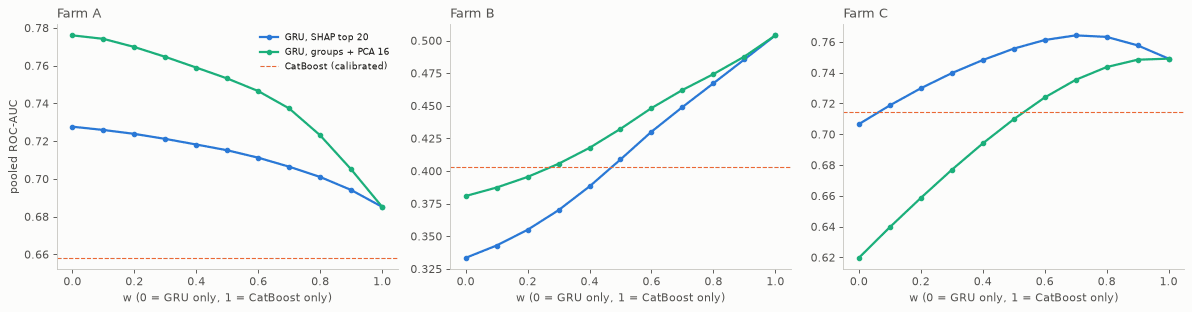

In [15]:
crow, erow, wrow = [], [], []
W_GRID = np.round(np.linspace(0, 1, 11), 2)
for f in FARMS:
    y = FEAT[f]["y7"].to_numpy(float)
    tu = FEAT[f]["turbine"].to_numpy()
    Ec = EVAL[(f, "CatBoost per farm")]["E"]
    for label, v in GRU_VARIANTS:
        Eg = EVAL[(f, label)]["E"]
        m = np.isfinite(y) & np.isfinite(Ec["score"]) & np.isfinite(Eg["score"])
        wt = [spearmanr(Ec["score"][m & (tu == t)], Eg["score"][m & (tu == t)])[0] for t in np.unique(tu[m])
              if (m & (tu == t)).sum() > 30]
        crow.append({"farm": f, "GRU": label, "Spearman, all days": spearmanr(Ec["score"][m], Eg["score"][m])[0],
                     "positive days": spearmanr(Ec["score"][m & (y == 1)], Eg["score"][m & (y == 1)])[0],
                     "negative days": spearmanr(Ec["score"][m & (y == 0)], Eg["score"][m & (y == 0)])[0],
                     "within turbine (mean)": np.nanmean(wt)})
        pc, pg = EVAL[(f, "CatBoost per farm")]["parts"], EVAL[(f, label)]["parts"]
        det = [(a[0], b[0]) for t in pc for a, b in zip(pc[t]["events"], pg[t]["events"])]
        erow.append({"farm": f, "GRU": label, "events": len(det), "both": sum(a and b for a, b in det),
                     "CatBoost only": sum(a and not b for a, b in det), "GRU only": sum(b and not a for a, b in det),
                     "neither": sum(not a and not b for a, b in det)})
        Z = []
        for fseed in SEEDS:
            zg, zc = np.full(len(y), np.nan), np.full(len(y), np.nan)
            for (ff, s, k), c in CB.items():
                if ff != f or s != fseed:
                    continue
                g = GRU_BY[(f, v, s, k)]
                tr = c["fold"] != k
                sel = np.isfinite(g["test"])
                for arr, (o, t) in ((zg, (g["oof"], g["test"])), (zc, (logit(c["oof"]), logit(c["test"])))):
                    vv = o[tr & np.isfinite(o)]
                    arr[sel] = (t[sel] - vv.mean()) / max(vv.std(), 1e-9)
            Z.append((zg, zc))
        zg, zc = np.mean([a for a, _ in Z], 0), np.mean([b for _, b in Z], 0)
        for w in W_GRID:
            s = w * zc + (1 - w) * zg
            mm = np.isfinite(y) & np.isfinite(s)
            wrow.append({"farm": f, "GRU": label, "w (CatBoost share)": w, "ROC-AUC pooled": roc_auc_score(y[mm], s[mm])})
CORR = pd.DataFrame(crow).set_index(["farm", "GRU"]).round(3)
display(CORR)
display(pd.DataFrame(erow).set_index(["farm", "GRU"]))
WC = pd.DataFrame(wrow)
display(WC.pivot_table(index="w (CatBoost share)", columns=["farm", "GRU"], values="ROC-AUC pooled").round(3))
CORR.to_csv(OUT2 / "results_correlation.csv")
WC.to_csv(OUT2 / "results_weight_curve.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, FARMS):
    for (label, v), color in zip(GRU_VARIANTS, (BLUE, AQUA)):
        h = WC[(WC["farm"] == f) & (WC["GRU"] == label)]
        ax.plot(h["w (CatBoost share)"], h["ROC-AUC pooled"], color=color, lw=2, marker="o", ms=4, label=label)
    ax.axhline(EVAL[(f, "CatBoost per farm")]["point"]["roc_auc"], color=ORANGE, lw=1, ls="--", label="CatBoost (calibrated)")
    ax.set_title(f"Farm {f}", loc="left", color=INK2)
    ax.set_xlabel("w (0 = GRU only, 1 = CatBoost only)")
axes[0].set_ylabel("pooled ROC-AUC")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT2 / "weight_curve.png", dpi=130, bbox_inches="tight")
show(fig)

## 12. Without temperatures (baseline rule 4), Farm A

Farm A is the farm where the GRU with groups and PCA beats CatBoost, and the farm whose label is most confounded with
season. Rule 4: the same GRU without the temperature group and without any temperature column in the PCA (ambient never
enters). The fair comparison is CatBoost per farm on its own `no_ambient_no_temp` features (baseline ablation, 0.688), as
well as CatBoost on all features (0.658).

In [16]:
NT = ("A", "grp_pca_notemp")
if NT not in GRU:
    t1 = time.time()
    GRU[NT] = Parallel(n_jobs=N_JOBS, backend="loky")(delayed(care_gru.run_job)(j) for j in make_jobs(*NT))
    pd.to_pickle(GRU, GRU_PATH)
    print(f"  GRU A grp_pca_notemp in {time.time() - t1:.0f} s")
GRU_BY.update({(r["farm"], r["variant"], r["seed"], r["k"]): r for r in GRU[NT]})
nt_label = "GRU, groups + PCA 16, no temperature"
r = evaluate(FEAT["A"], assemble("A", gru_parts("grp_pca_notemp")), "y7", EVENTS["A"])
r["matched"] = matched_eval(FEAT["A"], r["E"], ALL_META, "A")
EVAL[("A", nt_label)] = r
EVAL[("A", "CatBoost, no ambient, no temperature")] = evaluate(FEAT["A"], RUNS["A|no_ambient_no_temp|y7"], "y7", EVENTS["A"])
NTT = []
for label in ("CatBoost per farm", "CatBoost, no ambient, no temperature", "GRU, groups + PCA 16", nt_label):
    rr = EVAL[("A", label)]
    row = {"model": label, "ROC-AUC pooled [95% CI]": ci(rr, "roc_auc"),
           "within turbine": round(rr["point"]["within_turbine_auc"], 3),
           "event recall [95% CI]": ci(rr, "recall", "{:.2f}"),
           "false alarms / turbine-month": round(rr["point"]["fa_per_turbine_month"], 2)}
    if label == nt_label:
        row["vs CatBoost (all features)"] = paired("A", label, "CatBoost per farm", "roc_auc")[0]
        row["vs CatBoost (no temperature)"] = paired("A", label, "CatBoost, no ambient, no temperature", "roc_auc")[0]
        row["same-position dataset AUC"] = round(rr["matched"]["dataset AUC (max score)"], 3)
    NTT.append(row)
NTT = pd.DataFrame(NTT).set_index("model").fillna("")
display(NTT)
NTT.to_csv(OUT2 / "results_no_temperature_A.csv")

                                     ROC-AUC pooled [95% CI]  within turbine event recall [95% CI]  false alarms / turbine-month vs CatBoost (all features) vs CatBoost (no temperature) same-position dataset AUC
model                                                                                                                                                                                                             
CatBoost per farm                       0.658 [0.604, 0.756]           0.695     0.73 [0.60, 0.90]                          0.91                                                                                  
CatBoost, no ambient, no temperature    0.688 [0.637, 0.786]           0.728     0.73 [0.60, 0.90]                          0.93                                                                                  
GRU, groups + PCA 16                    0.756 [0.677, 0.876]           0.787     0.82 [0.69, 1.00]                          0.72                            

## 13. Verdict against the baseline rules (baseline section 8)

(1) pooled ROC-AUC, within-turbine ROC-AUC and event recall all above CatBoost per farm, with at most 1 false alarm per
turbine-month on the test turbines; (2) beats season only (paired interval above zero); (3) same-position dataset AUC above
CatBoost's; (4) without temperatures still above CatBoost's full-feature pooled ROC-AUC (run for Farm A only, section 12;
no ambient enters the GRU anywhere).

In [17]:
ver = []
for f in FARMS:
    b = EVAL[(f, "CatBoost per farm")]
    for label, _ in MODELS[2:]:
        r = EVAL[(f, label)]
        r1 = (r["point"]["roc_auc"] > b["point"]["roc_auc"] and r["point"]["within_turbine_auc"] > b["point"]["within_turbine_auc"]
              and r["point"]["recall"] > b["point"]["recall"] and r["point"]["fa_per_turbine_month"] <= FA_BUDGET)
        r2 = paired(f, label, "season only", "roc_auc")[1] == "yes"
        r3 = r["matched"]["dataset AUC (max score)"] > b["matched"]["dataset AUC (max score)"]
        r4 = (EVAL[("A", nt_label)]["point"]["roc_auc"] > b["point"]["roc_auc"]) if (f, label) == ("A", "GRU, groups + PCA 16") else None
        ver.append({"farm": f, "model": label, "1 metrics above CatBoost": r1, "2 beats season": r2,
                    "3 same position above CatBoost": r3, "4 without temperatures": "not run" if r4 is None else r4,
                    "passes 1-3": all([r1, r2, r3]),
                    "significantly above CatBoost (pooled)": paired(f, label, "CatBoost per farm", "roc_auc")[1]})
VER = pd.DataFrame(ver).set_index(["farm", "model"])
display(VER)
VER.to_csv(OUT2 / "results_verdict.csv")

                                             1 metrics above CatBoost  2 beats season  3 same position above CatBoost 4 without temperatures  passes 1-3 significantly above CatBoost (pooled)
farm model                                                                                                                                                                                    
A    GRU, SHAP top 20                                           False           False                            True                not run       False                                   yes
     GRU, groups + PCA 16                                        True           False                            True                   True       False                                   yes
     CatBoost + GRU (SHAP top 20) 50/50                         False           False                            True                not run       False                                   yes
     CatBoost + GRU (groups + PCA 16) 50/50  

## 14. Centring the scores on each turbine's own past

Within a turbine the models rank days better than across turbines (Farm B CatBoost: 0.550 within turbine against 0.403
pooled): turbines sit at different score levels, so a healthy turbine with a high level outranks a failing one with a low
level. Fix tried here, post-processing only, no retraining: subtract from each day's score (a logit) the median score of
the same timeline over the days [t-120, t-60), at least 30 scored days; the gap of 60 days keeps a developing fault out of
its own reference, as in the deviation baseline. Days without enough history get the median score of the training
turbines instead.

It only uses the turbine's past scores, so it runs in production as well (the model scores every day). The inner
out-of-fold scores are centred the same way, and the threshold and the calibration are refitted on them, so the pipeline is
unchanged. Prespecified: one window, chosen before seeing the result. Same-position test repeated, because a trailing
window could re-introduce the dataset-position leak.

In [18]:
REF_FROM, REF_TO, REF_MIN = 120, 60, 30


def centre(F_, s, fallback):
    """Score minus the median of the same timeline's scores on days [t-120, t-60)."""
    ser = pd.Series(s, index=F_.index)
    ref = ser.groupby(F_["segment"].to_numpy()).transform(
        lambda x: x.shift(REF_TO).rolling(REF_FROM - REF_TO, min_periods=REF_MIN).median())
    ref = ref.to_numpy()
    return s - np.where(np.isfinite(ref), ref, fallback)


def centred(fn, is_prob=False):
    def g(f, s_, k):
        o, t = fn(f, s_, k)
        if is_prob:
            o, t = logit(o), logit(t)
        tr = CB[(f, s_, k)]["fold"] != k
        fb = np.nanmedian(o[tr])
        return centre(FEAT[f], o, fb), centre(FEAT[f], t, fb)
    return g


CENTRE_MODELS = [("CatBoost per farm", centred(cb_parts, is_prob=True))]
CENTRE_MODELS += [(label, centred(gru_parts(v))) for label, v in GRU_VARIANTS]
CENTRE_MODELS += [(f"CatBoost + GRU ({label[5:]}) 50/50", centred(blend_parts(v))) for label, v in GRU_VARIANTS]
for f in FARMS:
    for label, fn in CENTRE_MODELS:
        r = evaluate(FEAT[f], assemble(f, fn), "y7", EVENTS[f])
        r["matched"] = matched_eval(FEAT[f], r["E"], ALL_META, f)
        EVAL[(f, label + ", centred")] = r

crows = []
for f in FARMS:
    for label, _ in CENTRE_MODELS:
        a, c = EVAL[(f, label)], EVAL[(f, label + ", centred")]
        crows.append({"farm": f, "model": label,
                      "pooled": round(a["point"]["roc_auc"], 3), "pooled, centred": round(c["point"]["roc_auc"], 3),
                      "centred - raw [95% CI]": paired(f, label + ", centred", label, "roc_auc")[0],
                      "within turbine": round(a["point"]["within_turbine_auc"], 3),
                      "within, centred": round(c["point"]["within_turbine_auc"], 3),
                      "event recall, centred": round(c["point"]["recall"], 2),
                      "false alarms, centred": round(c["point"]["fa_per_turbine_month"], 2),
                      "same position, centred": round(c["matched"]["dataset AUC (max score)"], 3),
                      "same position, raw": round(a["matched"]["dataset AUC (max score)"], 3)})
CEN = pd.DataFrame(crows).set_index(["farm", "model"])
display(CEN)
CEN.to_csv(OUT2 / "results_centred.csv")

                                             pooled  pooled, centred   centred - raw [95% CI]  within turbine  within, centred  event recall, centred  false alarms, centred  same position, centred  same position, raw
farm model                                                                                                                                                                                                              
A    CatBoost per farm                        0.658            0.598  -0.060 [-0.137, -0.033]           0.695            0.609                   0.73                   0.95                   0.636               0.645
     GRU, SHAP top 20                         0.716            0.687  -0.029 [-0.133, +0.057]           0.710            0.729                   0.73                   1.08                   0.777               0.785
     GRU, groups + PCA 16                     0.756            0.789  +0.033 [-0.083, +0.096]           0.787            0.810      

**Mean over the three farms** (simple mean of the farm values; Farm B, with every model below 0.5, pulls every mean down).

In [19]:
mrows = []
labels = [l for l, _ in MODELS[1:]] + [l + ", centred" for l, _ in CENTRE_MODELS]
for label in labels:
    pts = [EVAL[(f, label)]["point"] for f in FARMS]
    mrows.append({"model": label, **{f"pooled {f}": round(p["roc_auc"], 3) for f, p in zip(FARMS, pts)},
                  "mean pooled ROC-AUC": round(np.mean([p["roc_auc"] for p in pts]), 3),
                  "mean within-turbine ROC-AUC": round(np.mean([p["within_turbine_auc"] for p in pts]), 3),
                  "mean event recall": round(np.mean([p["recall"] for p in pts]), 2),
                  "mean false alarms": round(np.mean([p["fa_per_turbine_month"] for p in pts]), 2)})
MEANS = pd.DataFrame(mrows).set_index("model").sort_values("mean pooled ROC-AUC", ascending=False)
display(MEANS)
MEANS.to_csv(OUT2 / "results_mean_over_farms.csv")

                                                 pooled A  pooled B  pooled C  mean pooled ROC-AUC  mean within-turbine ROC-AUC  mean event recall  mean false alarms
model                                                                                                                                                                
CatBoost + GRU (groups + PCA 16) 50/50              0.735     0.405     0.690                0.610                        0.670               0.55               0.88
GRU, groups + PCA 16, centred                       0.789     0.453     0.569                0.604                        0.653               0.60               1.01
CatBoost + GRU (SHAP top 20) 50/50                  0.696     0.387     0.724                0.602                        0.669               0.59               0.96
CatBoost per farm                                   0.658     0.403     0.714                0.592                        0.658               0.64               1.07
GRU,

## 15. Recall against the false-alarm budget

The ROC-AUC does not depend on the threshold, so moving the threshold cannot change it; what moves is recall against false
alarms. Here the threshold is chosen, as everywhere in this notebook, on the inner out-of-fold scores of the training
turbines, but for several budgets: the lowest threshold that gives at most B false alarms per turbine-month there. The
alarm rule is unchanged (2 of the last 3 days above threshold, a continuing alarm notifies again every 7 days). Read on the
test turbines: event recall (an alarm between 7 days before onset and the end of the window), recall before onset (first
alarm at least one day before the logged onset), day recall, the realised false alarms, and the median lead time (onset day
minus first alarm day, negative = after onset).

=== CatBoost per farm


       day recall             event recall             false alarms / turbine-month             median lead (days)           recall before onset            
farm            A     B     C            A     B     C                            A     B     C                  A    B    C                   A     B     C
budget                                                                                                                                                      
0.5          0.37  0.00  0.32         0.64  0.00  0.56                         0.47  0.52  0.40                6.0  NaN  6.0                0.64  0.00  0.41
1.0          0.47  0.04  0.55         0.73  0.33  0.85                         0.91  1.23  1.06                7.0 -4.5  7.0                0.64  0.17  0.63
2.0          0.66  0.58  0.79         0.91  1.00  1.00                         2.35  2.59  2.39                7.0  4.5  7.0                0.82  0.83  0.93
3.0          0.76  0.82  0.86         1.00  1.00  1.00    

=== GRU, groups + PCA 16


       day recall             event recall             false alarms / turbine-month             median lead (days)           recall before onset           
farm            A     B     C            A     B     C                            A     B     C                  A    B    C                   A    B     C
budget                                                                                                                                                     
0.5          0.41  0.00  0.19         0.64  0.00  0.37                         0.55  0.37  0.41                7.0  NaN  7.0                0.64  0.0  0.26
1.0          0.46  0.00  0.28         0.82  0.00  0.44                         0.72  0.87  0.72                7.0  NaN  7.0                0.73  0.0  0.30
2.0          0.58  0.07  0.43         0.91  0.67  0.63                         1.00  1.86  1.32                7.0  6.0  7.0                0.73  0.5  0.44
3.0          0.62  0.14  0.50         0.91  0.67  0.70          

=== CatBoost + GRU (groups + PCA 16) 50/50


       day recall             event recall             false alarms / turbine-month             median lead (days)           recall before onset            
farm            A     B     C            A     B     C                            A     B     C                  A    B    C                   A     B     C
budget                                                                                                                                                      
0.5          0.36  0.00  0.29         0.55  0.00  0.48                         0.52  0.48  0.41                7.0  NaN  6.0                0.55  0.00  0.37
1.0          0.57  0.00  0.44         0.82  0.17  0.67                         0.90  1.01  0.75                7.0  7.0  7.0                0.73  0.17  0.48
2.0          0.70  0.15  0.62         0.91  0.67  0.85                         1.42  1.98  1.70                7.0  5.5  7.0                0.82  0.50  0.67
3.0          0.77  0.33  0.71         0.91  1.00  0.93    

=== mean over the three farms


                                               event recall  recall before onset  day recall  false alarms / turbine-month  median lead (days)
model                                  budget                                                                                                 
CatBoost + GRU (groups + PCA 16) 50/50 0.5             0.34                 0.31        0.22                          0.47                6.50
                                       1.0             0.55                 0.46        0.34                          0.88                7.00
                                       2.0             0.81                 0.66        0.49                          1.70                6.50
                                       3.0             0.95                 0.74        0.60                          2.17                5.00
                                       5.0             0.95                 0.74        0.60                          2.17                5.00

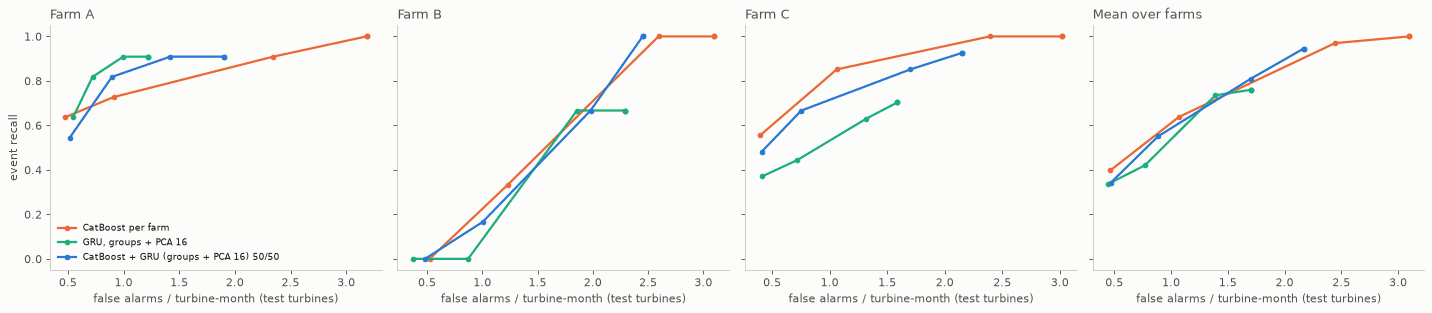

In [20]:
BUDGETS = [0.5, 1.0, 2.0, 3.0, 5.0, 8.0]
BUDGET_MODELS = [("CatBoost per farm", cb_parts), ("GRU, groups + PCA 16", gru_parts("grp_pca")),
                 ("CatBoost + GRU (groups + PCA 16) 50/50", blend_parts("grp_pca"))]
brows = []
for b in BUDGETS:
    FA_BUDGET = b
    for f in FARMS:
        for label, fn in BUDGET_MODELS:
            r = evaluate(FEAT[f], assemble(f, fn), "y7", EVENTS[f], n_boot=200)
            p = r["point"]
            lo, hi = np.nanpercentile(r["boot"]["recall"], [2.5, 97.5])
            brows.append({"budget": b, "farm": f, "model": label, "event recall": p["recall"],
                          "event recall 95% CI": f"[{lo:.2f}, {hi:.2f}]", "recall before onset": p["recall_before_onset"],
                          "day recall": p["day_recall"], "false alarms / turbine-month": p["fa_per_turbine_month"],
                          "median lead (days)": p["median_lead_days"], "events": p["events"]})
FA_BUDGET = 1.0
BUD = pd.DataFrame(brows)
BUD.to_csv(OUT2 / "results_budget_sweep.csv", index=False)
show_cols = ["event recall", "recall before onset", "day recall", "false alarms / turbine-month", "median lead (days)"]
for label, _ in BUDGET_MODELS:
    print(f"=== {label}")
    display(BUD[BUD["model"] == label].pivot_table(index="budget", columns="farm", values=show_cols).round(2))
MEANB = BUD.groupby(["model", "budget"])[show_cols].mean().round(2)
print("=== mean over the three farms")
display(MEANB)

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, f in zip(axes, FARMS + ["mean"]):
    for (label, _), color in zip(BUDGET_MODELS, (ORANGE, AQUA, BLUE)):
        h = BUD[BUD["model"] == label]
        h = h.groupby("budget")[["false alarms / turbine-month", "event recall"]].mean() if f == "mean" else h[h["farm"] == f].set_index("budget")
        ax.plot(h["false alarms / turbine-month"], h["event recall"], color=color, lw=2, marker="o", ms=4, label=label)
    ax.set_title("Mean over farms" if f == "mean" else f"Farm {f}", loc="left", color=INK2)
    ax.set_xlabel("false alarms / turbine-month (test turbines)")
axes[0].set_ylabel("event recall")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT2 / "recall_vs_false_alarms.png", dpi=130, bbox_inches="tight")
show(fig)

## 16. Confusion matrices of the two recommended set-ups

Day level, on the test turbines (out-of-fold, three-seed ensemble): the predicted class is an **alarm day** (2 of the last
3 days above the threshold), the true class is the k = 7 label (inside an anomaly window, or one starts within 7 days),
labelled usable days only. Two set-ups: **CatBoost per farm, threshold at a budget of 2 false alarms per turbine-month**
(the recall-first choice of section 15) and **CatBoost + GRU (groups + PCA 16) 50/50 at a budget of 1** (fewer false
alarms). One matrix per set-up: each farm's matrix is normalised by row (share of the true class), and the three farms are
averaged, so every farm weighs the same, as in the mean ROC-AUC. The table below keeps the counts per farm. Day recall
here counts days; the event recall of section 15 counts events (one alarm day in [onset - 7, end] catches the event).

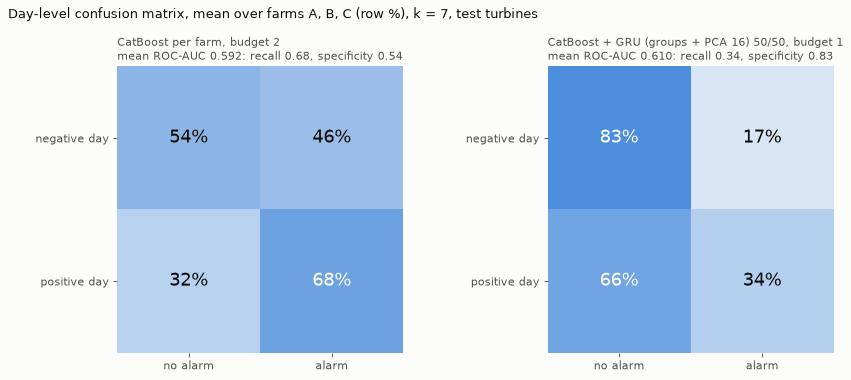

                                                          TN    FP   FN   TP  day recall  precision  specificity
set-up                                           farm                                                           
CatBoost per farm, budget 2                      A      2434  1685   69  134       0.660      0.074        0.591
                                                 B      1406  1519  120  164       0.577      0.097        0.481
                                                 C      6303  5364  130  492       0.791      0.084        0.540
                                                 all   10143  8568  319  790       0.712      0.084        0.542
CatBoost + GRU (groups + PCA 16) 50/50, budget 1 A      3399   720   88  115       0.567      0.138        0.825
                                                 B      2380   545  283    1       0.004      0.002        0.814
                                                 C      9980  1687  348  274       0.441      0.

In [21]:
from matplotlib.colors import LinearSegmentedColormap

SETUPS = [("CatBoost per farm, budget 2", cb_parts, 2.0),
          ("CatBoost + GRU (groups + PCA 16) 50/50, budget 1", blend_parts("grp_pca"), 1.0)]
CM = {}
for name, fn, b in SETUPS:
    FA_BUDGET = b
    for f in FARMS:
        r = evaluate(FEAT[f], assemble(f, fn), "y7", EVENTS[f], n_boot=0)
        y = FEAT[f]["y7"].to_numpy(float)
        m = np.isfinite(y) & np.isfinite(r["E"]["p"])
        yt, al = y[m].astype(int), r["E"]["alarm"][m].astype(int)
        CM[(name, f)] = np.array([[((yt == 0) & (al == 0)).sum(), ((yt == 0) & (al == 1)).sum()],
                                  [((yt == 1) & (al == 0)).sum(), ((yt == 1) & (al == 1)).sum()]])
    CM[(name, "all")] = sum(CM[(name, f)] for f in FARMS)
FA_BUDGET = 1.0

CMAP = LinearSegmentedColormap.from_list("seq", [SURFACE, BLUE])
cols = FARMS + ["all"]
rows_out = []
for name, _, _ in SETUPS:
    for f in cols:
        tn, fp, fn_, tp = CM[(name, f)].ravel()
        rows_out.append({"set-up": name, "farm": f, "TN": tn, "FP": fp, "FN": fn_, "TP": tp,
                         "day recall": round(tp / (tp + fn_), 3), "precision": round(tp / (tp + fp), 3) if tp + fp else np.nan,
                         "specificity": round(tn / (tn + fp), 3)})

# one matrix per model: the mean over the three farms of each farm's row-normalised matrix (every farm weighs the same)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, _, b_) in zip(axes, SETUPS):
    pct = np.mean([CM[(name, f)] / CM[(name, f)].sum(axis=1, keepdims=True) for f in FARMS], axis=0)
    ax.imshow(pct, cmap=CMAP, vmin=0, vmax=1)
    for i_ in range(2):
        for c in range(2):
            ax.text(c, i_, f"{100 * pct[i_, c]:.0f}%", ha="center", va="center", fontsize=16,
                    color=SURFACE if pct[i_, c] > 0.55 else INK)
    ax.set_xticks([0, 1], ["no alarm", "alarm"])
    ax.set_yticks([0, 1], ["negative day", "positive day"])
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    auc_mean = np.mean([EVAL[(f, name.split(", budget")[0])]["point"]["roc_auc"] for f in FARMS])
    ax.set_title(f"{name}\nmean ROC-AUC {auc_mean:.3f}: recall {pct[1, 1]:.2f}, specificity {pct[0, 0]:.2f}",
                 loc="left", color=INK2, fontsize=10)
fig.suptitle("Day-level confusion matrix, mean over farms A, B, C (row %), k = 7, test turbines", x=0.01, ha="left",
             color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(OUT2 / "confusion_matrices.png", dpi=130, bbox_inches="tight")
show(fig, dpi=80)
CMT = pd.DataFrame(rows_out).set_index(["set-up", "farm"])
display(CMT)
CMT.to_csv(OUT2 / "results_confusion.csv")

## 17. Minimising false negatives: threshold set for a target recall

False negatives alone are minimised by alarming every day, so a target is needed: **catch a fixed share of the positive
days (80%, 90% or 95%) and see which model does it with the fewest false alarms.** In every outer fold the threshold is
the score that reaches the target day recall on the inner out-of-fold scores of the training turbines (the test turbines
never set it). A day alarms as soon as its score reaches the threshold (no 2-of-3 persistence, which delays alarms and
adds false negatives); with three fold seeds a day alarms when a majority of seeds alarm.

One more model enters here: **CatBoost per farm without ambient and temperature features** (the best CatBoost on the
mean over farms, baseline ablation 0.688 / 0.384 / 0.733), refitted to get its inner scores, alone and blended 50/50 with
the GRU (groups + PCA 16).

In [22]:
CBNT_PATH = OUT2 / "catboost_inner_notemp.pkl"
CBNT = pd.read_pickle(CBNT_PATH) if CBNT_PATH.exists() and not REBUILD_CB else {}
for f in FARMS:
    folds_f = sorted(FOLDS.query("scheme == 'per_farm' and farm == @f")["fold"].unique())
    for fseed in SEEDS:
        for k in folds_f:
            if (f, fseed, k) not in CBNT:
                CBNT[(f, fseed, k)] = cb_fold(FEAT[f], SETS[f]["no_ambient_no_temp"], fseed, k)
    pd.to_pickle(CBNT, CBNT_PATH)
chk = []
for f in FARMS:
    old = RUNS[f"{f}|no_ambient_no_temp|y7"]["pred"]
    for fseed in SEEDS:
        new = np.nanmax(np.stack([v["test"] for (ff, s_, _), v in CBNT.items() if ff == f and s_ == fseed]), axis=0)
        b_ = old[old["seed"] == fseed].sort_values("row")["score"].to_numpy()
        m = np.isfinite(new) | np.isfinite(b_)
        chk.append(float(np.nanmax(np.abs(new[m] - b_[m]))))
print("CatBoost without temperatures, max |score difference| vs the baseline ablation run:", max(chk))


def cbnt_parts(f, s_, k):
    return CBNT[(f, s_, k)]["oof"], CBNT[(f, s_, k)]["test"]


def blend_with(cbdict, variant):
    def fn(f, s_, k):
        g, c = GRU_BY[(f, variant, s_, k)], cbdict[(f, s_, k)]
        tr = c["fold"] != k
        zo, zt = {}, {}
        for key, (o, t) in {"g": (g["oof"], g["test"]), "c": (logit(c["oof"]), logit(c["test"]))}.items():
            v = o[tr & np.isfinite(o)]
            mu, sd = v.mean(), max(v.std(), 1e-9)
            zo[key], zt[key] = (o - mu) / sd, (t - mu) / sd
        return 0.5 * zo["g"] + 0.5 * zo["c"], 0.5 * zt["g"] + 0.5 * zt["c"]
    return fn


FN_MODELS = [("CatBoost per farm", cb_parts), ("CatBoost, no ambient, no temperature", cbnt_parts),
             ("GRU, groups + PCA 16", gru_parts("grp_pca")),
             ("CatBoost + GRU (groups + PCA 16) 50/50", blend_parts("grp_pca")),
             ("CatBoost no temperature + GRU (groups + PCA 16) 50/50", blend_with(CBNT, "grp_pca"))]
TARGETS = [0.80, 0.90, 0.95]


def recall_alarms(f, fn, target):
    """Majority-of-seeds alarm days with a threshold reaching `target` day recall on the inner scores; also seed-mean score."""
    F_ = FEAT[f]
    y = F_["y7"].to_numpy(float)
    votes, scores = [], []
    for fseed in SEEDS:
        al, sc = np.zeros(len(F_), bool), np.full(len(F_), np.nan)
        for (ff, s_, k), v in CB.items():
            if ff != f or s_ != fseed:
                continue
            te, tr = v["fold"] == k, v["fold"] != k
            oof, test = fn(f, fseed, k)
            pos_s = oof[tr & (y == 1) & np.isfinite(oof)]
            thr = np.quantile(pos_s, 1 - target)
            sel = te & np.isfinite(test)
            al[sel] = test[sel] >= thr
            sc[sel] = test[sel]
        votes.append(al)
        scores.append(sc)
    return np.mean(votes, 0) >= 0.5, np.nanmean(scores, 0)


frows = []
for f in FARMS:
    F_ = FEAT[f]
    y = F_["y7"].to_numpy(float)
    for label, fn in FN_MODELS:
        auc_f = None
        for target in TARGETS:
            alarm, score = recall_alarms(f, fn, target)
            m = np.isfinite(y) & np.isfinite(score)
            if auc_f is None:
                auc_f = roc_auc_score(y[m], score[m])
            yt, al = y[m].astype(int), alarm[m]
            tp, fn_, fp, tn = ((yt == 1) & al).sum(), ((yt == 1) & ~al).sum(), ((yt == 0) & al).sum(), ((yt == 0) & ~al).sum()
            parts, _ = per_turbine_parts(F_, EVENTS[f], np.nan_to_num(score), alarm, "y7")
            evs = [d for v in parts.values() for d, _ in v["events"]]
            frows.append({"farm": f, "model": label, "target day recall": target, "ROC-AUC": auc_f,
                          "false negative days %": 100 * fn_ / (fn_ + tp), "alarm on normal days %": 100 * fp / (fp + tn),
                          "precision %": 100 * tp / max(tp + fp, 1), "events missed": int(len(evs) - np.sum(evs)),
                          "events": len(evs), "TN": tn, "FP": fp, "FN": fn_, "TP": tp})
FNT = pd.DataFrame(frows)
FNT.to_csv(OUT2 / "results_recall_target.csv", index=False)
show_c = ["false negative days %", "alarm on normal days %", "precision %", "events missed"]
for target in TARGETS:
    print(f"=== target day recall {target:.0%} (threshold set on the training turbines), per farm")
    display(FNT[FNT["target day recall"] == target].pivot_table(index="model", columns="farm", values=show_c).round(1))
MEANF = FNT.groupby(["target day recall", "model"]).agg(**{
    "mean ROC-AUC": ("ROC-AUC", "mean"), "false negative days % (mean)": ("false negative days %", "mean"),
    "alarm on normal days % (mean)": ("alarm on normal days %", "mean"), "precision % (mean)": ("precision %", "mean"),
    "events missed (of 44)": ("events missed", "sum")}).round(2)
print("=== mean over the three farms")
display(MEANF)
MEANF.to_csv(OUT2 / "results_recall_target_mean.csv")

CatBoost without temperatures, max |score difference| vs the baseline ablation run: 0.0


=== target day recall 80% (threshold set on the training turbines), per farm


                                                      alarm on normal days %             events missed           false negative days %             precision %           
farm                                                                       A     B     C             A    B    C                     A     B     C           A     B    C
model                                                                                                                                                                    
CatBoost + GRU (groups + PCA 16) 50/50                                  44.4  75.5  53.0           0.0  0.0  1.0                  21.2  11.6  22.2         8.0  10.2  7.3
CatBoost no temperature + GRU (groups + PCA 16) 50/50                   49.1  74.8  50.9           0.0  0.0  1.0                  20.7  26.8  22.2         7.4   8.7  7.5
CatBoost per farm                                                       79.6  84.7  66.9           0.0  0.0  0.0                  12.8   1.1  11.1    

=== target day recall 90% (threshold set on the training turbines), per farm


                                                      alarm on normal days %             events missed           false negative days %             precision %          
farm                                                                       A     B     C             A    B    C                     A     B     C           A    B    C
model                                                                                                                                                                   
CatBoost + GRU (groups + PCA 16) 50/50                                  62.5  83.8  79.0           0.0  0.0  0.0                  17.2   4.9   8.4         6.1  9.9  5.8
CatBoost no temperature + GRU (groups + PCA 16) 50/50                   64.9  85.4  77.1           0.0  0.0  0.0                  17.7  11.6   8.7         5.9  9.1  5.9
CatBoost per farm                                                       89.9  91.1  82.1           0.0  0.0  0.0                   0.5   0.0   8.2         

=== target day recall 95% (threshold set on the training turbines), per farm


                                                      alarm on normal days %             events missed           false negative days %            precision %          
farm                                                                       A     B     C             A    B    C                     A     B    C           A    B    C
model                                                                                                                                                                  
CatBoost + GRU (groups + PCA 16) 50/50                                  72.8  89.3  85.3           0.0  0.0  0.0                  14.8   3.9  8.2         5.5  9.5  5.4
CatBoost no temperature + GRU (groups + PCA 16) 50/50                   73.4  91.2  84.8           0.0  0.0  0.0                  15.8   9.2  7.7         5.4  8.8  5.5
CatBoost per farm                                                       94.3  95.1  85.7           0.0  0.0  0.0                   0.0   0.0  6.4         5.0  9

=== mean over the three farms


                                                                         mean ROC-AUC  false negative days % (mean)  alarm on normal days % (mean)  precision % (mean)  events missed (of 44)
target day recall model                                                                                                                                                                      
0.80              CatBoost + GRU (groups + PCA 16) 50/50                         0.63                         18.33                          57.64                8.50                      1
                  CatBoost no temperature + GRU (groups + PCA 16) 50/50          0.62                         23.21                          58.27                7.86                      1
                  CatBoost per farm                                              0.64                          8.32                          77.05                7.31                      0
                  CatBoost, no ambient, no tempera

## 18. Production model for ML1: CatBoost + GRU (groups + PCA 16) 50/50

Chosen as the ML1 model (best mean ROC-AUC over the farms, 0.610). The production models are refitted on **all**
turbines of each farm, with the settings the cross-validation chose: CatBoost with the median number of trees of the
outer folds (three seeds, probabilities averaged), the GRU with the median number of epochs (three seeds x two networks,
logits averaged), and the preprocessing (log1p, standardisation, PCA) fitted on all labelled days. The blend
standardisation, the isotonic calibration and the thresholds come from the **out-of-fold** scores of section 10, so they
describe the model on turbines it has not seen:

- `budget_1`: at most 1 false alarm per turbine-month with the 2-of-3-days alarm rule (apply the rule to the flags);
- `recall_80`, `recall_90`: the score reaching 80% / 90% day recall, alarm on the first day above it.

Files in `models/ml1/` (each under the repository's 500 KB limit): `catboost_<farm>_seed<s>.cbm`, `gru_<farm>.pt`
(state dicts), `gru_preprocess_<farm>.npz`, and `ml1_contract.json` (features, settings, blend, calibration, thresholds,
cross-validated scores). Scoring: `care_gru.ml1_scores` in `fault_detection/care_gru.py`. The scores are checked below
against a direct recomputation, and on the training data (in-sample, so optimistic: a pipeline check, not a result).

In [23]:
import json

import torch

ML1_DIR = ROOT / "models" / "ml1"
ML1_DIR.mkdir(parents=True, exist_ok=True)
GCFG = dict(care_gru.DEFAULTS)
contract = {"model": "ML1 fault risk: CatBoost per farm + GRU (groups + PCA 16), 50/50 blend of standardised logits",
            "target": "k = 7: day t is inside an anomaly window, or one starts within the next 7 days",
            "features": ("daily deviation table of notebooks/care_catboost_baseline.ipynb sections 1-5 (|rz| of every "
                         "sensor against its operating-point model on the trailing baseline [t-180, t-60), daily mean and "
                         "95th percentile, group aggregates); rows sorted by timeline and day"),
            "source": "notebooks/care_gru.ipynb section 18; results in notebooks/care_gru.md",
            "alarm_rules": {"budget_1": "2 of the last 3 days at or above the threshold",
                            "recall_80": "any day at or above the threshold", "recall_90": "any day at or above the threshold"},
            "farms": {}}
for f in FARMS:
    F_ = FEAT[f]
    y = F_["y7"].to_numpy(float)
    lab, usable = np.isfinite(y), F_["usable"].to_numpy()
    fit = lab & usable
    yz = np.nan_to_num(y)
    pos = seg_position(F_)
    feats = SETS[f]["full"]
    X = F_[feats].to_numpy(np.float32)
    n_trees = int(np.median([v["n_star"] for (ff, _, _), v in CB.items() if ff == f]))
    cb_files, p_cb = [], []
    for s_ in SEEDS:
        m = CatBoostClassifier(**dict(CB_PARAMS, iterations=n_trees), random_seed=s_)
        m.fit(X[fit], y[fit])
        fn_ = f"catboost_{f}_seed{s_}.cbm"
        m.save_model(str(ML1_DIR / fn_))
        cb_files.append(fn_)
        p_cb.append(m.predict_proba(X)[:, 1])
    cols, grp = candidates(f)
    gin = grp + ["ctx_ws", "ctx_p"] + [f"{c}__m" for c in DEV_COLS[f]]
    n_fixed = len(grp) + 2
    Xg = F_[gin].to_numpy(np.float32)
    logc = np.array([i for i, c in enumerate(gin) if not c.startswith("ctx_")])
    pcac = np.arange(n_fixed, len(gin))
    fit_rows, neg_rows = np.flatnonzero(fit), np.flatnonzero(fit & (yz == 0))
    pre = care_gru.fit_preprocess(Xg, logc, fit_rows, neg_rows, pcac, GCFG["n_pca"])
    Z, miss = care_gru.apply_preprocess(Xg, pre)
    idx = care_gru.window_index(pos, GCFG["window"])
    w = event_weights(F_, EVENTS[f])
    n_ep = int(np.median([r["n_epochs"] for r in GRU[(f, "grp_pca")]]))
    states, lg = [], []
    xall, _ = care_gru.gather(Z, miss, idx, np.arange(len(F_)))
    for s_ in SEEDS:
        for ns in GCFG["net_seeds"]:
            net, _, _, _ = care_gru.train_one(Z, miss, idx, yz, w, fit_rows, neg_rows, GCFG, 1000 * s_ + ns, epochs=n_ep)
            states.append({k_: v_.clone() for k_, v_ in net.state_dict().items()})
            lg.append(care_gru.predict(net, xall))
    torch.save(states, ML1_DIR / f"gru_{f}.pt")
    np.savez(ML1_DIR / f"gru_preprocess_{f}.npz", **pre)

    # blend standardisation, calibration and thresholds from the out-of-fold scores (seed-mean of the outer test scores)
    oof_c = np.nanmean([logit(np.nanmax(np.stack([v["test"] for (ff, s2, _), v in CB.items() if ff == f and s2 == s_]), 0))
                        for s_ in SEEDS], axis=0)
    oof_g = np.nanmean([np.nanmax(np.stack([GRU_BY[(f, "grp_pca", s_, k)]["test"] for (ff, s2, k) in CB if ff == f and s2 == s_]), 0)
                        for s_ in SEEDS], axis=0)
    ok = fit & np.isfinite(oof_c) & np.isfinite(oof_g)
    b = dict(cb_mu=float(oof_c[ok].mean()), cb_sd=float(oof_c[ok].std()), gru_mu=float(oof_g[ok].mean()),
             gru_sd=float(oof_g[ok].std()))
    oof_b = 0.5 * (oof_c - b["cb_mu"]) / b["cb_sd"] + 0.5 * (oof_g - b["gru_mu"]) / b["gru_sd"]
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof_b[ok], y[ok])
    FA_BUDGET = 1.0
    thr = {"budget_1": choose_threshold(np.where(ok, oof_b, np.nan), np.where(ok, y, np.nan), pos),
           "recall_80": float(np.quantile(oof_b[ok & (y == 1)], 0.20)),
           "recall_90": float(np.quantile(oof_b[ok & (y == 1)], 0.10))}
    gru_meta = {k_: GCFG[k_] for k_ in ("window", "hidden", "dropout", "n_pca")}
    contract["farms"][f] = {
        "catboost_files": cb_files, "catboost_features": feats, "catboost_trees": n_trees,
        "catboost_params": {k_: v_ for k_, v_ in CB_PARAMS.items() if k_ not in ("thread_count", "verbose", "allow_writing_files")},
        "gru_file": f"gru_{f}.pt", "gru_preprocess_file": f"gru_preprocess_{f}.npz", "gru_inputs": gin,
        "gru": dict(gru_meta, epochs=n_ep, networks=len(states)),
        "blend": b, "calibration": {"x": iso.X_thresholds_.tolist(), "y": iso.y_thresholds_.tolist()},
        "thresholds": {k_: float(v_) for k_, v_ in thr.items()},
        "cv_out_of_fold": {"roc_auc_pooled": round(EVAL[(f, "CatBoost + GRU (groups + PCA 16) 50/50")]["point"]["roc_auc"], 3),
                           "roc_auc_within_turbine": round(EVAL[(f, "CatBoost + GRU (groups + PCA 16) 50/50")]["point"]["within_turbine_auc"], 3),
                           "events": int(EVAL[(f, "CatBoost + GRU (groups + PCA 16) 50/50")]["point"]["events"])},
    }
    # direct in-sample score, for the check below
    z_c = logit(np.mean(p_cb, 0))
    contract["farms"][f]["_check"] = 0.5 * (z_c - b["cb_mu"]) / b["cb_sd"] + 0.5 * (np.mean(lg, 0) - b["gru_mu"]) / b["gru_sd"]
    print(f"farm {f}: CatBoost {n_trees} trees x3, GRU {n_ep} epochs x{len(states)}, thresholds "
          + ", ".join(f"{k_} {v_:.3f}" for k_, v_ in thr.items()))

checks = {f: contract["farms"][f].pop("_check") for f in FARMS}
(ML1_DIR / "ml1_contract.json").write_text(json.dumps(contract, indent=1) + "\n")
FA_BUDGET = 1.0

rows = []
for f in FARMS:
    F_ = FEAT[f]
    sc, risk, al = care_gru.ml1_scores(F_, f, ML1_DIR, seg_position(F_))
    y = F_["y7"].to_numpy(float)
    m = np.isfinite(y) & F_["usable"].to_numpy()
    rows.append({"farm": f, "max |score - direct|": float(np.nanmax(np.abs(sc - checks[f]))),
                 "in-sample ROC-AUC (optimistic)": round(roc_auc_score(y[m], sc[m]), 3),
                 "CV out-of-fold ROC-AUC": contract["farms"][f]["cv_out_of_fold"]["roc_auc_pooled"],
                 "mean risk": round(float(np.mean(risk[m])), 3)})
display(pd.DataFrame(rows).set_index("farm"))
sizes = pd.DataFrame([{"file": p.name, "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(ML1_DIR.iterdir())])
display(sizes)
assert sizes["KB"].max() < 500, "a model file is above the repository's 500 KB limit"
print(f"total run time {time.time() - T0:.0f} s")

farm A: CatBoost 49 trees x3, GRU 7 epochs x6, thresholds budget_1 0.619, recall_80 -0.283, recall_90 -0.786


farm B: CatBoost 30 trees x3, GRU 2 epochs x6, thresholds budget_1 0.959, recall_80 -0.578, recall_90 -0.718


farm C: CatBoost 68 trees x3, GRU 2 epochs x6, thresholds budget_1 0.615, recall_80 -0.206, recall_90 -0.570


      max |score - direct|  in-sample ROC-AUC (optimistic)  CV out-of-fold ROC-AUC  mean risk
farm                                                                                         
A                      0.0                           0.981                   0.735      0.058
B                      0.0                           0.960                   0.405      0.095
C                      0.0                           0.980                   0.690      0.054

                    file     KB
0              README.md    3.3
1   catboost_A_seed0.cbm   31.8
2   catboost_A_seed1.cbm   31.8
3   catboost_A_seed2.cbm   31.8
4   catboost_B_seed0.cbm   32.1
5   catboost_B_seed1.cbm   32.1
6   catboost_B_seed2.cbm   32.1
7   catboost_C_seed0.cbm   85.2
8   catboost_C_seed1.cbm   85.0
9   catboost_C_seed2.cbm   85.3
10              gru_A.pt   96.0
11              gru_B.pt  100.5
12              gru_C.pt  105.0
13  gru_preprocess_A.npz   10.9
14  gru_preprocess_B.npz   20.5
15  gru_preprocess_C.npz   76.4
16     ml1_contract.json  100.6

total run time 288 s
